<center><h1>Yi_Jiahe_HW2</h1></center>
<br>
<center><font size="4">Combined Cycle Power Plant Data Set</font></center>

Name: Jiahe Yi
<br>
Github Username: beaverjuly
<br>
USC ID: 5689143499

---

**How to run:** open this notebook from the repository root and use
`Kernel -> Restart & Run All`. All paths are **relative** and use forward
slashes only, so no edits are needed to execute it.

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [1]:
# ----------------------------------------------------------------------
# All imports for the entire notebook live in this single cell.
# ----------------------------------------------------------------------
import os
import warnings
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")

# ---- reproducibility -------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- plotting defaults -----------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"

# ---- pandas display --------------------------------------------------
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)

BLUE, RED, GREEN = "#2E86AB", "#D1495B", "#5B8C5A"

print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("matplotlib  :", plt.matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("statsmodels :", sm.__version__)
import sklearn
print("scikit-learn:", sklearn.__version__)

numpy       : 2.4.4
pandas      : 3.0.2
matplotlib  : 3.10.8
seaborn     : 0.13.2
statsmodels : 0.15.0
scikit-learn: 1.8.0


Get the Cycle Power Plant Data Set

The Combined Cycle Power Plant (CCPP) data set is downloaded from the UCI
Machine Learning Repository
(<https://archive.ics.uci.edu/ml/datasets/Combined+Cycle+Power+Plant>) and
stored in this repository under `data/ccpp_data/`, so the notebook runs offline.

As footnote 1 of the assignment instructs, the workbook contains five sheets
that are shuffled copies of the same data, and we **work with Sheet 1**.

In [2]:
# ----------------------------------------------------------------------
# Load the data using a RELATIVE path with forward slashes only.
# ----------------------------------------------------------------------
DATA_PATH_CANDIDATES = [
    "data/ccpp_data/Folds5x2_pp.xlsx",
    "../data/ccpp_data/Folds5x2_pp.xlsx",
]


def resolve_path(candidates):
    """Return the first existing relative path from `candidates`."""
    for path in candidates:
        if os.path.exists(path):
            return path
    raise FileNotFoundError(
        "Could not find Folds5x2_pp.xlsx. Looked in: " + ", ".join(candidates)
    )


DATA_PATH = resolve_path(DATA_PATH_CANDIDATES)
print("Loading data from:", DATA_PATH)

# Footnote 1: all five sheets are shuffles of the same data - use Sheet 1.
df = pd.read_excel(DATA_PATH, sheet_name="Sheet1")

PREDICTORS = ["AT", "V", "AP", "RH"]
RESPONSE = "PE"

print("\nSheets in the workbook:", pd.ExcelFile(DATA_PATH).sheet_names)
print("Shape of Sheet1:", df.shape)
print("Missing values :", int(df.isna().sum().sum()))
df.head()

Loading data from: data/ccpp_data/Folds5x2_pp.xlsx



Sheets in the workbook: ['Sheet1', 'Sheet2', 'Sheet3', 'Sheet4', 'Sheet5']
Shape of Sheet1: (9568, 5)
Missing values : 0


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


### (b) Exploring the data

#### i. rows and columns

In [3]:
# ----------------------------------------------------------------------
# (b) i. How many rows and columns? What do they represent?
# ----------------------------------------------------------------------
n_rows, n_cols = df.shape
print(f"Number of rows    : {n_rows}")
print(f"Number of columns : {n_cols}")

meaning = pd.DataFrame(
    [
        ("AT", "Temperature",          "degrees C", "predictor", "ambient, affects gas turbine"),
        ("V",  "Exhaust Vacuum",       "cm Hg",     "predictor", "collected from the steam turbine"),
        ("AP", "Ambient Pressure",     "millibar",  "predictor", "ambient, affects gas turbine"),
        ("RH", "Relative Humidity",    "%",         "predictor", "ambient, affects gas turbine"),
        ("PE", "Net hourly electrical energy output", "MW", "RESPONSE", "the quantity we predict"),
    ],
    columns=["Column", "Meaning", "Units", "Role", "Note"],
)
print()
print(meaning.to_string(index=False))

Number of rows    : 9568
Number of columns : 5

Column                             Meaning     Units      Role                             Note
    AT                         Temperature degrees C predictor     ambient, affects gas turbine
     V                      Exhaust Vacuum     cm Hg predictor collected from the steam turbine
    AP                    Ambient Pressure  millibar predictor     ambient, affects gas turbine
    RH                   Relative Humidity         % predictor     ambient, affects gas turbine
    PE Net hourly electrical energy output        MW  RESPONSE          the quantity we predict


**Answer to (b) i.**

The data set has **9568 rows** and **5 columns**.

* **Rows** — each row is one *hourly average* observation of the power plant,
  collected over six years (2006–2011) while the plant was running at full load.
  There are 9568 such hours in the data.
* **Columns** — four are **predictors** (the ambient variables `AT`, `V`, `AP`,
  `RH`) and one is the **response**, `PE`, the net hourly electrical energy
  output in MW. `V` is measured at and affects the steam turbine; the other
  three ambient variables affect the gas turbine.

#### ii. pairwise scatterplots of all the varianbles

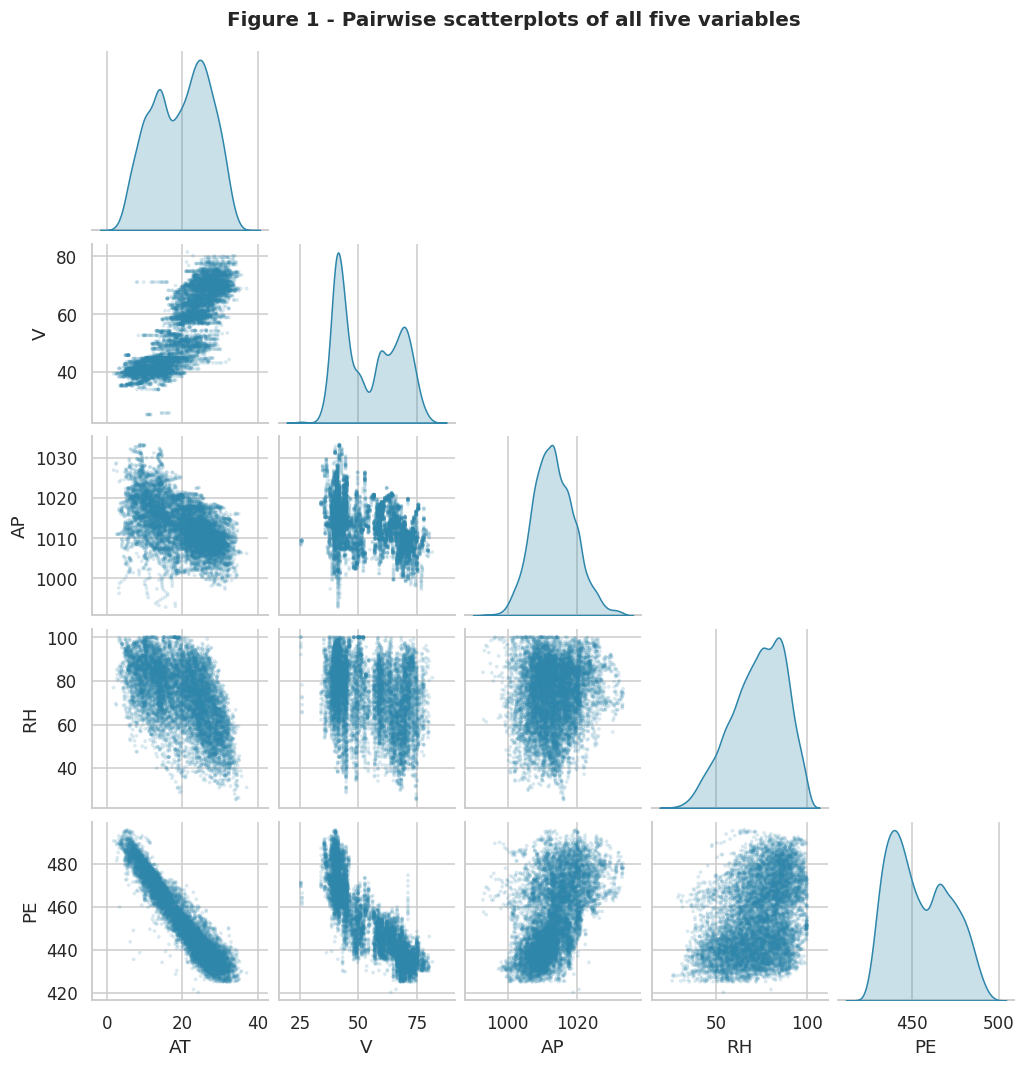

In [4]:
# ----------------------------------------------------------------------
# (b) ii. Pairwise scatterplots of ALL variables (predictors + response).
# ----------------------------------------------------------------------
grid = sns.pairplot(
    df,
    corner=True,
    diag_kind="kde",
    plot_kws=dict(s=6, alpha=0.18, edgecolor="none", color=BLUE),
    diag_kws=dict(color=BLUE, fill=True),
    height=1.9,
)
grid.figure.suptitle(
    "Figure 1 - Pairwise scatterplots of all five variables",
    y=1.02, fontsize=13, fontweight="bold",
)
plt.show()

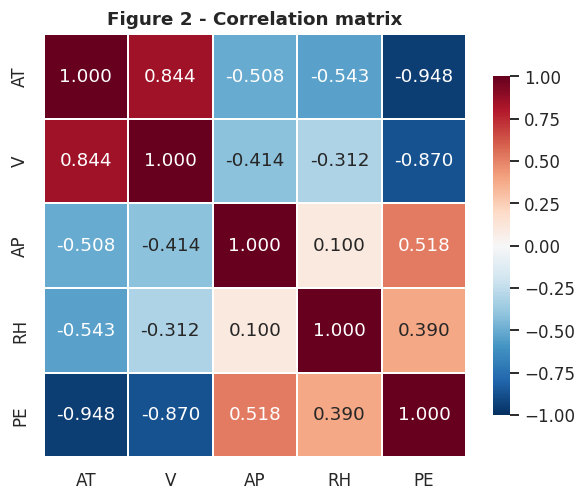

Correlation of each predictor with the response PE:
AT   -0.948128
V    -0.869780
RH    0.389794
AP    0.518429


In [5]:
# Correlation matrix to put numbers behind the visual impressions.
corr = df.corr()

fig, ax = plt.subplots(figsize=(6.2, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, linewidths=1, linecolor="white",
            cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Figure 2 - Correlation matrix")
plt.show()

print("Correlation of each predictor with the response PE:")
print(corr[RESPONSE].drop(RESPONSE).sort_values().to_string())

**Answer to (b) ii — findings.**

* **`AT` (temperature) is by far the strongest predictor of `PE`**, with a
  correlation of $-0.948$. The relationship is strongly negative and close to
  linear: hotter ambient air means less electrical output. A mild downward curve
  is visible at the extremes, which anticipates part (f).
* **`V` (exhaust vacuum) is the second strongest**, correlation $-0.870$, also
  negative. Its scatter against `PE` is noticeably banded rather than a single
  cloud.
* **`AP` (ambient pressure) is positively associated** with `PE` ($+0.518$) and
  **`RH` (relative humidity) weakly positively** ($+0.390$). Both show wide
  vertical spread — on their own they explain little.
* **The predictors are correlated with each other.** `AT` and `V` are strongly
  positively correlated ($+0.844$), and `AT` is negatively correlated with both
  `AP` ($-0.507$) and `RH` ($-0.542$). This multicollinearity is what makes
  parts (d) and (e) interesting: a predictor's simple-regression coefficient
  will not survive unchanged into the multiple regression.
* **Marginal distributions.** The diagonal panels show that `AT`, `V` and the
  response `PE` are all **bimodal** — `V` most strikingly so. This may reflect
  distinct environmental or operating regimes, though the data contain no time
  variable, so we cannot establish that from this file alone. `AP` is close to
  symmetric and unimodal, and `RH` is unimodal but left-skewed.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [6]:
# ----------------------------------------------------------------------
# (b) iii. Summary statistics for every variable, in one table.
# ----------------------------------------------------------------------
summary = pd.DataFrame({
    "Mean":    df.mean(),
    "Median":  df.median(),
    "Min":     df.min(),
    "Max":     df.max(),
    "Range":   df.max() - df.min(),
    "Q1":      df.quantile(0.25),
    "Q3":      df.quantile(0.75),
})
summary["IQR"] = summary["Q3"] - summary["Q1"]
summary.index.name = "Variable"

print("Summary statistics for all five variables")
print("=" * 96)
print(summary.round(3).to_string())
print("=" * 96)

Summary statistics for all five variables
              Mean    Median     Min      Max  Range        Q1       Q3     IQR
Variable                                                                       
AT          19.651    20.345    1.81    37.11  35.30    13.510    25.72  12.210
V           54.306    52.080   25.36    81.56  56.20    41.740    66.54  24.800
AP        1013.259  1012.940  992.89  1033.30  40.41  1009.100  1017.26   8.160
RH          73.309    74.975   25.56   100.16  74.60    63.328    84.83  21.502
PE         454.365   451.550  420.26   495.76  75.50   439.750   468.43  28.680


**Answer to (b) iii.**

| Variable | Mean | Median | Range (min – max) | Q1 | Q3 | IQR |
|---|---|---|---|---|---|---|
| `AT` (°C) | 19.651 | 20.345 | 35.30 (1.81 – 37.11) | 13.510 | 25.720 | 12.210 |
| `V` (cm Hg) | 54.306 | 52.080 | 56.20 (25.36 – 81.56) | 41.740 | 66.540 | 24.800 |
| `AP` (mbar) | 1013.259 | 1012.940 | 40.41 (992.89 – 1033.30) | 1009.100 | 1017.260 | 8.160 |
| `RH` (%) | 73.309 | 74.975 | 74.60 (25.56 – 100.16) | 63.328 | 84.830 | 21.502 |
| `PE` (MW) | 454.365 | 451.550 | 75.50 (420.26 – 495.76) | 439.750 | 468.430 | 28.680 |

Two observations worth carrying forward:

* **The variables differ in both level and spread.** For a distance-based
  method such as the KNN regression in part (i), only the **spread** matters:
  Euclidean distance is built from *differences*, so each variable's mean
  cancels out. By standard deviation the order is
  `RH` (14.60) > `V` (12.71) > `AT` (7.45) > `AP` (5.94). So `AP` — despite
  having by far the largest values, near 1013 — actually contributes the
  *least* to raw distances, while `RH` contributes the most. This is quantified
  in part (i).
* **Mean vs median.** `V` has mean 54.3 but median 52.1 (right-skewed), while
  `AT` and `RH` have medians above their means (mildly left-skewed).

### (c) Simple Linear Regression

For each predictor $X$ we fit
$$\text{PE} = \beta_0 + \beta_1 X + \varepsilon$$
and test $H_0:\beta_1 = 0$ against $H_1:\beta_1 \neq 0$.

In [7]:
# ----------------------------------------------------------------------
# (c) Fit one simple linear regression per predictor.
# ----------------------------------------------------------------------
simple_models = {}
rows = []

for p in PREDICTORS:
    model = smf.ols(f"{RESPONSE} ~ {p}", data=df).fit()
    simple_models[p] = model
    rows.append({
        "Predictor": p,
        "Intercept": model.params["Intercept"],
        "Slope": model.params[p],
        "Std err": model.bse[p],
        "t": model.tvalues[p],
        "p-value": model.pvalues[p],
        "R^2": model.rsquared,
        "RSE": np.sqrt(model.scale),
    })

simple_tab = pd.DataFrame(rows).set_index("Predictor")

print("Simple linear regression: PE ~ each predictor")
print("=" * 104)
print(simple_tab.round(6).to_string())
print("=" * 104)
print("\nAll four p-values are far below any conventional threshold "
      "(reported as 0.000e+00 = smaller than float64 can represent).")

Simple linear regression: PE ~ each predictor
             Intercept     Slope   Std err           t  p-value       R^2        RSE
Predictor                                                                           
AT          497.034120 -2.171320  0.007443 -291.715195      0.0  0.898948   5.425666
V           517.801526 -1.168135  0.006776 -172.401540      0.0  0.756518   8.421964
AP        -1055.260989  1.489872  0.025126   59.296232      0.0  0.268769  14.595103
RH          420.961766  0.455650  0.011006   41.398730      0.0  0.151939  15.717852

All four p-values are far below any conventional threshold (reported as 0.000e+00 = smaller than float64 can represent).


In [8]:
# Full statsmodels summary for the strongest predictor, as an illustration.
print(simple_models["AT"].summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:31:27   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    497.0341      0.156   3177.280      0.0

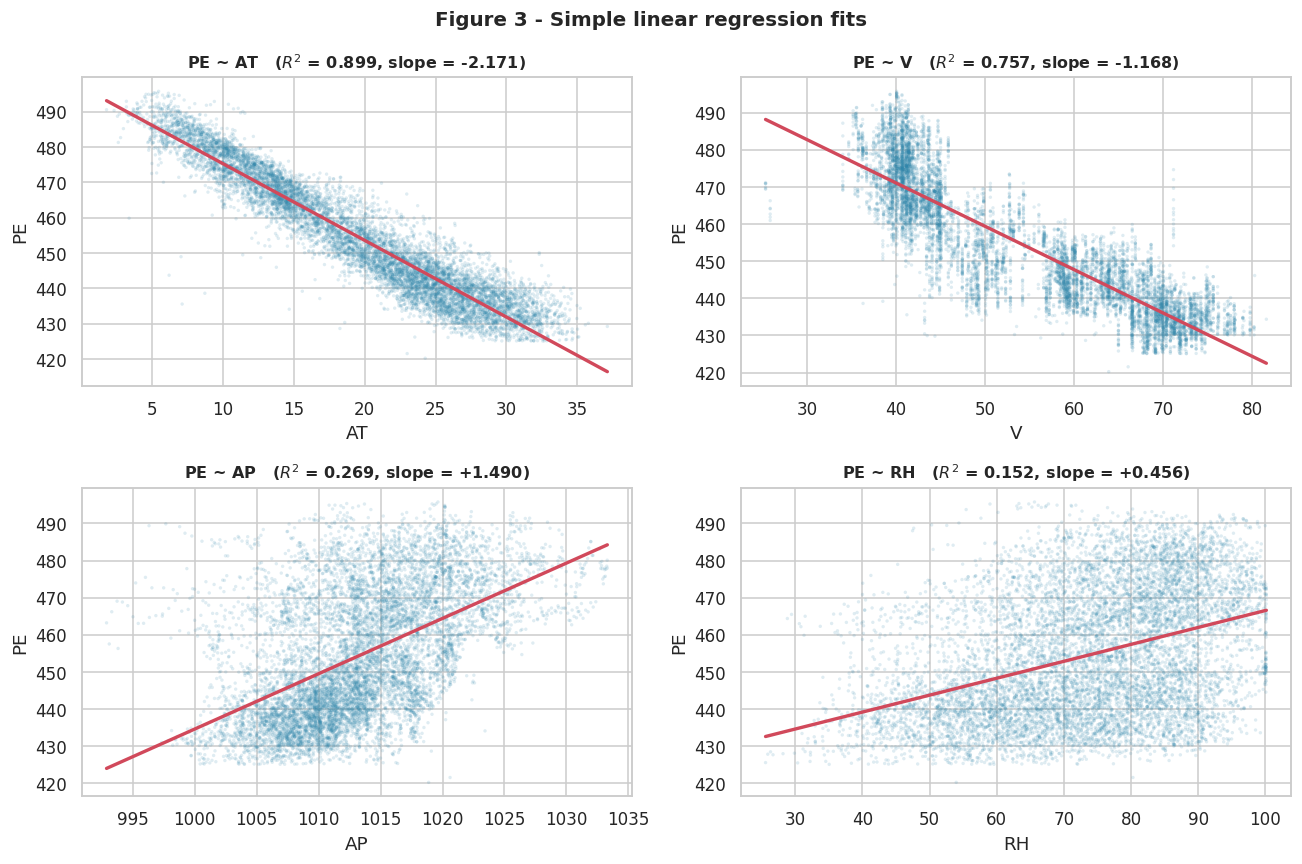

In [9]:
# ----------------------------------------------------------------------
# Plot each simple regression fit.
# ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, p in zip(axes.ravel(), PREDICTORS):
    ax.scatter(df[p], df[RESPONSE], s=5, alpha=0.15, color=BLUE,
               edgecolor="none", rasterized=True)
    xs = np.linspace(df[p].min(), df[p].max(), 200)
    m = simple_models[p]
    ys = m.params["Intercept"] + m.params[p] * xs
    ax.plot(xs, ys, color=RED, lw=2.2)
    ax.set_xlabel(p)
    ax.set_ylabel(RESPONSE)
    ax.set_title(f"PE ~ {p}   ($R^2$ = {m.rsquared:.3f}, slope = {m.params[p]:+.3f})",
                 fontsize=10.5)

fig.suptitle("Figure 3 - Simple linear regression fits", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

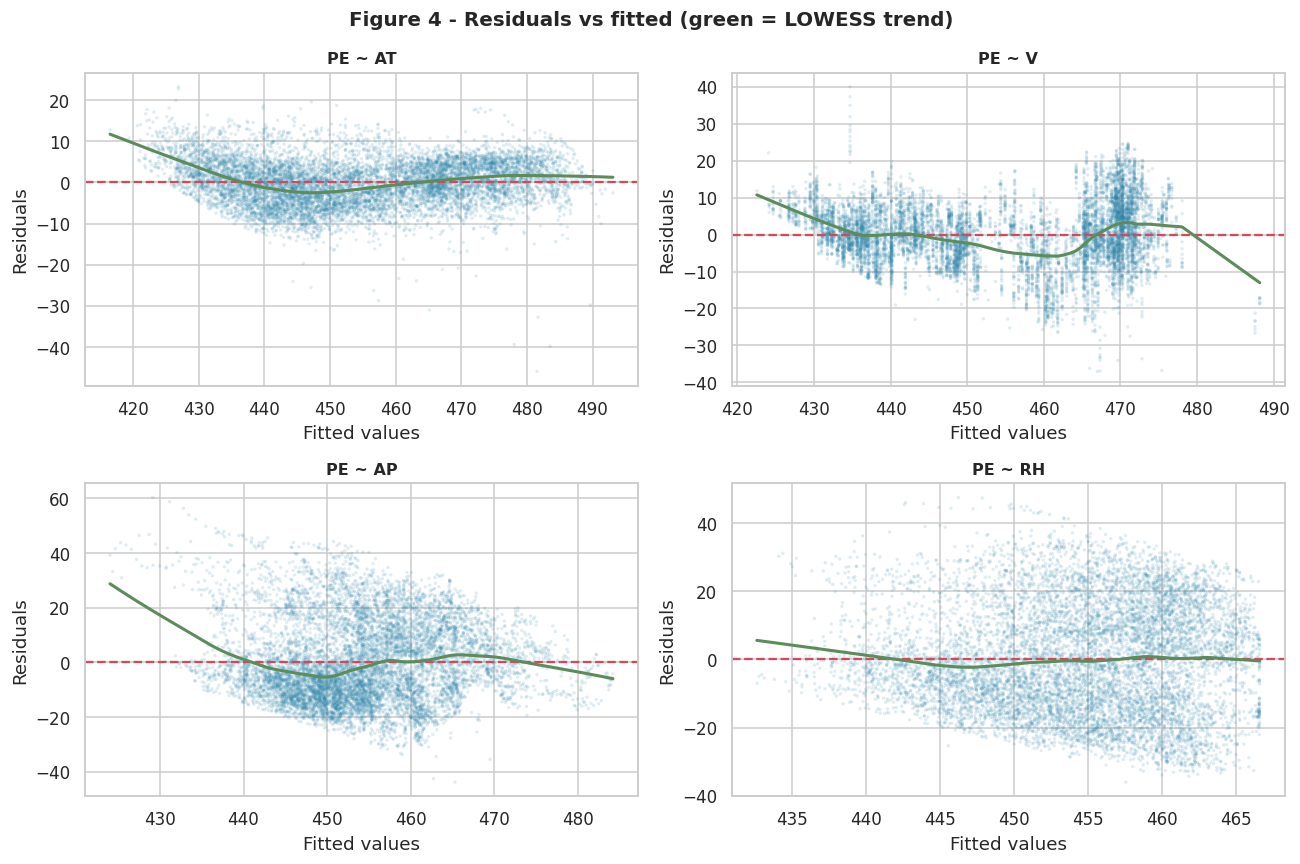

In [10]:
# ----------------------------------------------------------------------
# Residual diagnostics - do the simple models satisfy the OLS assumptions?
# ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, p in zip(axes.ravel(), PREDICTORS):
    m = simple_models[p]
    ax.scatter(m.fittedvalues, m.resid, s=5, alpha=0.15, color=BLUE,
               edgecolor="none", rasterized=True)
    ax.axhline(0, color=RED, lw=1.5, ls="--")
    # LOWESS trend makes any curvature obvious.
    lo = sm.nonparametric.lowess(m.resid, m.fittedvalues, frac=0.3)
    ax.plot(lo[:, 0], lo[:, 1], color=GREEN, lw=2)
    ax.set_xlabel("Fitted values")
    ax.set_ylabel("Residuals")
    ax.set_title(f"PE ~ {p}", fontsize=10.5)

fig.suptitle("Figure 4 - Residuals vs fitted (green = LOWESS trend)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

In [11]:
# ----------------------------------------------------------------------
# Outlier diagnostics for each simple regression.
#   - externally studentized residuals: |t| > 3  -> unusual in y
#   - Cook's distance: D > 4/n                   -> influential overall
# ----------------------------------------------------------------------
out_rows = []
outlier_masks = {}

for p in PREDICTORS:
    m = simple_models[p]
    infl = m.get_influence()
    stud = infl.resid_studentized_external
    cooks = infl.cooks_distance[0]

    mask = np.abs(stud) > 3
    outlier_masks[p] = mask

    # Refit without the flagged points to see whether they actually matter.
    refit = smf.ols(f"{RESPONSE} ~ {p}", data=df[~mask]).fit()

    out_rows.append({
        "Predictor": p,
        "|stud res| > 3": int(mask.sum()),
        "% of data": 100 * mask.mean(),
        "Cook's D > 4/n": int((cooks > 4 / len(df)).sum()),
        "Slope (all)": m.params[p],
        "Slope (trimmed)": refit.params[p],
        "Slope change %": 100 * abs(refit.params[p] - m.params[p]) / abs(m.params[p]),
        "R^2 (all)": m.rsquared,
        "R^2 (trimmed)": refit.rsquared,
    })

outlier_tab = pd.DataFrame(out_rows).set_index("Predictor")
print("Outlier diagnostics, and the effect of removing the flagged points")
print("=" * 118)
print(outlier_tab.round(4).to_string())
print("=" * 118)

Outlier diagnostics, and the effect of removing the flagged points
           |stud res| > 3  % of data  Cook's D > 4/n  Slope (all)  Slope (trimmed)  Slope change %  R^2 (all)  R^2 (trimmed)
Predictor                                                                                                                   
AT                     42     0.4390             416      -2.1713          -2.1802          0.4102     0.8989         0.9064
V                      33     0.3449             423      -1.1681          -1.1769          0.7494     0.7565         0.7670
AP                     30     0.3135             300       1.4899           1.5401          3.3683     0.2688         0.2864
RH                      2     0.0209             249       0.4557           0.4564          0.1644     0.1519         0.1526


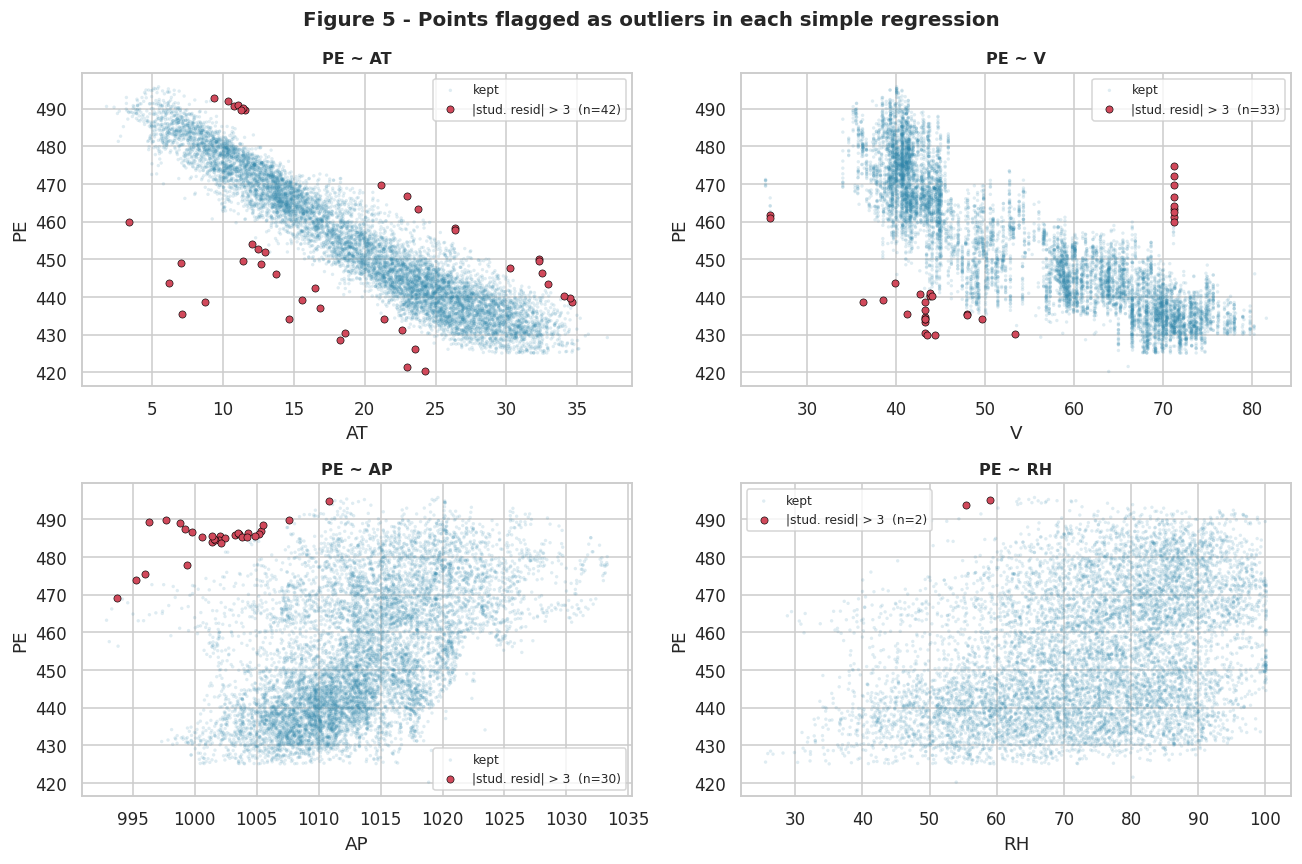

In [12]:
# Visualise the flagged points.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, p in zip(axes.ravel(), PREDICTORS):
    mask = outlier_masks[p]
    ax.scatter(df.loc[~mask, p], df.loc[~mask, RESPONSE], s=5, alpha=0.15,
               color=BLUE, edgecolor="none", label="kept", rasterized=True)
    ax.scatter(df.loc[mask, p], df.loc[mask, RESPONSE], s=22, color=RED,
               edgecolor="black", lw=0.4, label=f"|stud. resid| > 3  (n={mask.sum()})")
    ax.set_xlabel(p)
    ax.set_ylabel(RESPONSE)
    ax.set_title(f"PE ~ {p}", fontsize=10.5)
    ax.legend(fontsize=8, loc="best")

fig.suptitle("Figure 5 - Points flagged as outliers in each simple regression",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

**Answer to (c).**

**Results.** Every one of the four simple regressions finds a statistically
significant association:

| Predictor | Slope | $t$ | $p$-value | $R^2$ |
|---|---|---|---|---|
| `AT` | $-2.1713$ | $-291.7$ | $< 10^{-300}$ | **0.899** |
| `V` | $-1.1681$ | $-172.4$ | $< 10^{-300}$ | 0.757 |
| `AP` | $+1.4899$ | $+59.3$ | $< 10^{-300}$ | 0.269 |
| `RH` | $+0.4557$ | $+41.4$ | $< 10^{-300}$ | 0.152 |

**In which models is the association statistically significant?**
**All four.** Every $p$-value is numerically zero in double precision, so we
reject $H_0: \beta_1 = 0$ in every case. With $n = 9568$, however, significance
is almost guaranteed — the far more informative quantity is $R^2$. `AT` alone
explains 89.9% of the variation in `PE`, whereas `RH` explains only 15.2%.
Statistical significance and practical usefulness are not the same thing here.

**What the plots show.**
* Figure 3: `AT` and `V` give tight, clearly linear bands; `AP` and `RH` give
  diffuse clouds around a shallow trend.
* Figure 4: the LOWESS curves are not flat. `AT` shows systematic curvature at
  both ends, and `V` shows a pronounced wave — direct evidence that a
  straight line is not the right functional form. This motivates part (f).

**Outliers.** Using $|{\text{studentized residual}}| > 3$:

| Predictor | Flagged | % of data | Slope change if removed |
|---|---|---|---|
| `AT` | 42 | 0.44% | 0.41% |
| `V` | 33 | 0.34% | 0.75% |
| `AP` | 30 | 0.31% | 3.37% |
| `RH` | 2 | 0.02% | 0.16% |

**Would I remove them? No.** Three reasons:

1. **They barely matter.** Removing them changes each slope by less than 3.4%
   and the sign and significance not at all. With $n = 9568$ no handful of
   points can dominate the fit.
2. **They are not errors.** These are real hourly readings within physically
   plausible ranges, not data-entry mistakes. They are "outliers" only relative
   to a straight-line model that we already suspect is misspecified.
3. **Figure 4 suggests the model is the problem, not the data.** Much of the
   apparent outlyingness comes from fitting a line to a curved relationship.
   The right response is to improve the model — which is exactly what parts
   (f), (g) and (h) do — not to delete inconvenient observations.

We therefore keep all 9568 rows for the remainder of the assignment.

### (d) Multiple Regression

In [13]:
# ----------------------------------------------------------------------
# (d) Multiple regression using all four predictors.
# ----------------------------------------------------------------------
multiple_model = smf.ols(f"{RESPONSE} ~ AT + V + AP + RH", data=df).fit()
print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:32:06   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    454.6093      9.749     46.634      0.0

In [14]:
# Compact view of the coefficient table plus a significance flag.
mult_tab = pd.DataFrame({
    "Coefficient": multiple_model.params,
    "Std err": multiple_model.bse,
    "t": multiple_model.tvalues,
    "p-value": multiple_model.pvalues,
})
mult_tab["Reject H0: beta_j = 0 at 0.05?"] = np.where(
    mult_tab["p-value"] < 0.05, "YES", "no")

print("Multiple regression: PE ~ AT + V + AP + RH")
print("=" * 92)
print(mult_tab.round(6).to_string())
print("=" * 92)
print(f"\nR^2                  : {multiple_model.rsquared:.4f}")
print(f"Adjusted R^2         : {multiple_model.rsquared_adj:.4f}")
print(f"Residual std error   : {np.sqrt(multiple_model.scale):.4f} MW")
print(f"F-statistic          : {multiple_model.fvalue:.1f}  (p = {multiple_model.f_pvalue:.3e})")

# Variance inflation factors quantify the multicollinearity seen in (b) ii.
X_vif = sm.add_constant(df[PREDICTORS])
vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=PREDICTORS, name="VIF")
print("\nVariance inflation factors:")
print(vif.round(3).to_string())

Multiple regression: PE ~ AT + V + AP + RH
           Coefficient   Std err           t  p-value Reject H0: beta_j = 0 at 0.05?
Intercept   454.609274  9.748512   46.633709      0.0                            YES
AT           -1.977513  0.015289 -129.342024      0.0                            YES
V            -0.233916  0.007282  -32.122109      0.0                            YES
AP            0.062083  0.009458    6.564086      0.0                            YES
RH           -0.158054  0.004168  -37.918473      0.0                            YES

R^2                  : 0.9287
Adjusted R^2         : 0.9287
Residual std error   : 4.5583 MW
F-statistic          : 31138.3  (p = 0.000e+00)

Variance inflation factors:
AT    5.978
V     3.943
AP    1.453
RH    1.705


**Answer to (d).**

$$\widehat{\text{PE}} = 454.609 - 1.9775\,\text{AT} - 0.2339\,\text{V}
+ 0.0621\,\text{AP} - 0.1581\,\text{RH}$$

**For which predictors can we reject $H_0: \beta_j = 0$? All four of them.**

| Predictor | Coefficient | $t$ | $p$-value | Reject $H_0$? |
|---|---|---|---|---|
| `AT` | $-1.9775$ | $-129.34$ | $<0.001$ | **Yes** |
| `V` | $-0.2339$ | $-32.12$ | $<0.001$ | **Yes** |
| `AP` | $+0.0621$ | $+6.56$ | $5.5\times10^{-11}$ | **Yes** |
| `RH` | $-0.1581$ | $-37.92$ | $<0.001$ | **Yes** |

**Description of the results.**

* The model explains **92.87%** of the variance in `PE` ($R^2 = 0.9287$,
  adjusted $R^2$ identical to four decimals because $n \gg p$). The overall
  $F$-statistic is 31138 with $p \approx 0$, so the predictors are jointly
  highly significant.
* The residual standard error is **4.56 MW**, against a response that ranges
  over 75.5 MW — a good fit.
* `AT` carries most of the explanatory power: holding the others fixed, a 1 °C
  rise in ambient temperature is associated with a **1.98 MW drop** in output.
* `AP` is significant but small: a 1 mbar rise is associated with only a
  0.062 MW increase.
* The VIFs are modest (all below 6), so although the predictors are correlated,
  the collinearity is not severe enough to destabilise the coefficient
  estimates.

### (e) 1c Compare to 1d

In [15]:
# ----------------------------------------------------------------------
# (e) Univariate coefficients (x-axis) vs multiple coefficients (y-axis).
# ----------------------------------------------------------------------
coef_compare = pd.DataFrame({
    "Simple (1c)": [simple_models[p].params[p] for p in PREDICTORS],
    "Multiple (1d)": [multiple_model.params[p] for p in PREDICTORS],
}, index=PREDICTORS)
coef_compare["Difference"] = coef_compare["Multiple (1d)"] - coef_compare["Simple (1c)"]
coef_compare["Sign flip?"] = np.where(
    np.sign(coef_compare["Simple (1c)"]) != np.sign(coef_compare["Multiple (1d)"]),
    "YES", "no")

print("Univariate vs multiple regression coefficients")
print("=" * 78)
print(coef_compare.round(4).to_string())
print("=" * 78)

Univariate vs multiple regression coefficients
    Simple (1c)  Multiple (1d)  Difference Sign flip?
AT      -2.1713        -1.9775      0.1938         no
V       -1.1681        -0.2339      0.9342         no
AP       1.4899         0.0621     -1.4278         no
RH       0.4557        -0.1581     -0.6137        YES


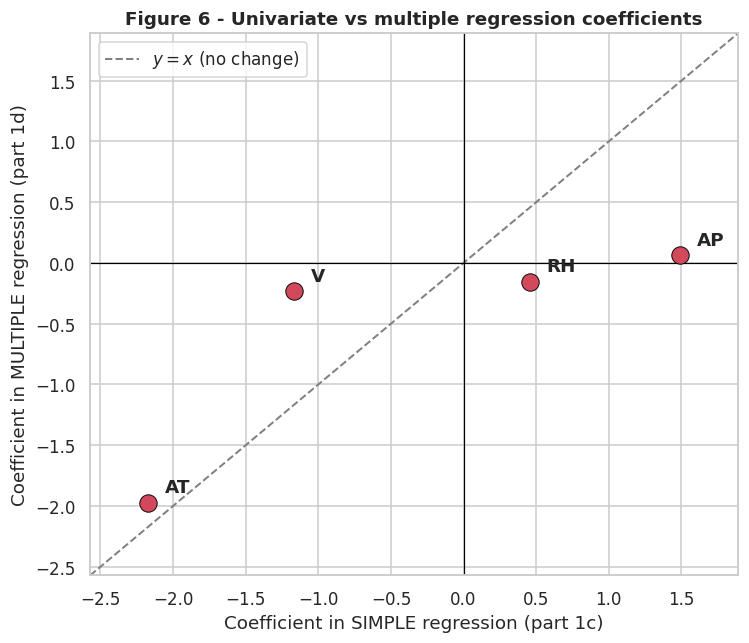

In [16]:
fig, ax = plt.subplots(figsize=(7.6, 6.4))

xs = coef_compare["Simple (1c)"].values
ys = coef_compare["Multiple (1d)"].values

ax.scatter(xs, ys, s=130, color=RED, zorder=5, edgecolor="black", lw=0.6)
for name, x, y in zip(coef_compare.index, xs, ys):
    ax.annotate(name, (x, y), textcoords="offset points", xytext=(11, 7),
                fontsize=12, fontweight="bold")

# y = x reference line: points on it are unchanged by the other predictors.
lim = [min(xs.min(), ys.min()) - 0.4, max(xs.max(), ys.max()) + 0.4]
ax.plot(lim, lim, ls="--", color="grey", lw=1.3, label="$y = x$ (no change)")
ax.axhline(0, color="black", lw=0.8)
ax.axvline(0, color="black", lw=0.8)

ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Coefficient in SIMPLE regression (part 1c)")
ax.set_ylabel("Coefficient in MULTIPLE regression (part 1d)")
ax.set_title("Figure 6 - Univariate vs multiple regression coefficients")
ax.legend(loc="upper left")
plt.show()

**Answer to (e).**

| Predictor | Simple (1c) | Multiple (1d) | Change |
|---|---|---|---|
| `AT` | $-2.1713$ | $-1.9775$ | shrinks slightly |
| `V` | $-1.1681$ | $-0.2339$ | shrinks by 80% |
| `AP` | $+1.4899$ | $+0.0621$ | shrinks by 96% |
| `RH` | $+0.4557$ | $-0.1581$ | **flips sign** |

**How the results compare.** Only `AT` keeps roughly the same coefficient. The
other three change dramatically, and `RH` even reverses direction. In Figure 6
this shows up as three of the four points lying far off the $y = x$ line, with
`RH` sitting in a different quadrant entirely.

**Why this happens.** A simple regression coefficient absorbs the effect of
every variable correlated with that predictor; a multiple regression
coefficient estimates the effect of that predictor *holding the others fixed*.
The two answer different questions, and they can differ substantially when the
predictors are correlated. Here they are strongly correlated (part (b) ii).

`RH` is the clearest case. On its own, higher humidity looks associated with
*higher* output ($+0.456$), but humidity is strongly negatively correlated with
temperature ($r = -0.542$), and temperature drives output down hard. The simple
regression for `RH` is mostly picking up "humid hours tend to be cool hours".
Once `AT` is in the model and temperature is held fixed, the genuine partial
association of humidity is **negative** ($-0.158$).

This is confounding, and it is the reason the multiple regression coefficients
are the ones to interpret.

### (f) Nonlinear Association

For each predictor $X$ we fit the cubic model
$$\text{PE} = \beta_0 + \beta_1 X + \beta_2 X^2 + \beta_3 X^3 + \varepsilon$$
and ask whether the nonlinear terms add anything.

**A numerical caution.** Raw powers of these variables are enormously
ill-conditioned — `AP` is around 1013, so $\text{AP}^3 \approx 1.04\times10^9$,
and the design matrix has condition number $2.1\times10^{15}$, which exceeds
what double precision can resolve. Fitting raw powers therefore returns a
*wrong* $R^2$ for `AP`. We standardise each predictor before forming powers,
which spans the **identical model space** but is numerically stable. Both fits
are shown below so the discrepancy is visible.

The formal test of nonlinearity is the **nested $F$-test** comparing the linear
model against the cubic model; it is invariant to this reparameterisation.

In [17]:
# ----------------------------------------------------------------------
# (f) Demonstrate the conditioning problem with raw powers.
# ----------------------------------------------------------------------
cond_rows = []
for p in PREDICTORS:
    x = df[p].values
    X_raw = np.column_stack([np.ones_like(x), x, x**2, x**3])
    z = (x - x.mean()) / x.std()
    X_std = np.column_stack([np.ones_like(z), z, z**2, z**3])

    def r2_of(X):
        beta, *_ = np.linalg.lstsq(X, df[RESPONSE].values, rcond=None)
        resid = df[RESPONSE].values - X @ beta
        return 1 - (resid**2).sum() / ((df[RESPONSE] - df[RESPONSE].mean())**2).sum()

    cond_rows.append({
        "Predictor": p,
        "cond(raw powers)": np.linalg.cond(X_raw),
        "cond(standardised)": np.linalg.cond(X_std),
        "R^2 raw": r2_of(X_raw),
        "R^2 standardised": r2_of(X_std),
        "R^2 differs?": "YES" if abs(r2_of(X_raw) - r2_of(X_std)) > 1e-8 else "no",
    })

cond_tab = pd.DataFrame(cond_rows).set_index("Predictor")
print("Conditioning of the cubic design matrix")
print("=" * 100)
print(cond_tab.to_string(float_format=lambda v: f"{v:,.6g}"))
print("=" * 100)
print("\nFor AP the two R^2 values disagree: the raw-power fit is numerically")
print("corrupted (cond = 2.1e15 is beyond float64 resolution). We therefore")
print("report the standardised parameterisation, which is the same model.")

Conditioning of the cubic design matrix
           cond(raw powers)  cond(standardised)  R^2 raw  R^2 standardised R^2 differs?
Predictor                                                                              
AT                  190,245             5.49949 0.911883          0.911883           no
V               2.47382e+07             5.46133 0.775022          0.775022           no
AP                 2.12e+15             6.70178 0.274863          0.297543          YES
RH              3.25888e+07             6.79115 0.153743          0.153743           no

For AP the two R^2 values disagree: the raw-power fit is numerically
corrupted (cond = 2.1e15 is beyond float64 resolution). We therefore
report the standardised parameterisation, which is the same model.


In [18]:
# ----------------------------------------------------------------------
# (f) Fit the cubic model for each predictor (standardised, stable) and
#     test it against the linear model with a nested F-test.
# ----------------------------------------------------------------------
poly_models, poly_rows = {}, []

for p in PREDICTORS:
    work = pd.DataFrame({
        RESPONSE: df[RESPONSE],
        "z": (df[p] - df[p].mean()) / df[p].std(),
    })
    linear = smf.ols(f"{RESPONSE} ~ z", data=work).fit()
    cubic = smf.ols(f"{RESPONSE} ~ z + I(z**2) + I(z**3)", data=work).fit()
    poly_models[p] = cubic

    anova = sm.stats.anova_lm(linear, cubic)
    poly_rows.append({
        "Predictor": p,
        "p(X^2)": cubic.pvalues["I(z ** 2)"],
        "p(X^3)": cubic.pvalues["I(z ** 3)"],
        "R^2 linear": linear.rsquared,
        "R^2 cubic": cubic.rsquared,
        "R^2 gain": cubic.rsquared - linear.rsquared,
        "F (linear vs cubic)": anova["F"].iloc[1],
        "p (F-test)": anova["Pr(>F)"].iloc[1],
    })

poly_tab = pd.DataFrame(poly_rows).set_index("Predictor")
print("Cubic models (predictors standardised before forming powers)")
print("=" * 118)
print(poly_tab.to_string(float_format=lambda v: f"{v:,.4g}"))
print("=" * 118)

Cubic models (predictors standardised before forming powers)
              p(X^2)     p(X^3)  R^2 linear  R^2 cubic  R^2 gain  F (linear vs cubic)  p (F-test)
Predictor                                                                                        
AT        3.312e-231 3.652e-110      0.8989     0.9119   0.01294                  702  3.478e-285
V         8.977e-131    0.01373      0.7565      0.775    0.0185                393.3   7.04e-165
AP         2.193e-46  2.123e-67      0.2688     0.2975   0.02877                195.9   4.209e-84
RH            0.1014   1.44e-05      0.1519     0.1537  0.001803                10.19     3.8e-05


In [19]:
# Show the full coefficient table for one predictor as an illustration.
print("Example - cubic model for AT (z = standardised AT):\n")
print(poly_models["AT"].summary().tables[1])

Example - cubic model for AT (z = standardised AT):

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    452.7081      0.074   6085.240      0.000     452.562     452.854
z            -18.1075      0.108   -167.160      0.000     -18.320     -17.895
I(z ** 2)      1.8080      0.054     33.381      0.000       1.702       1.914
I(z ** 3)      1.1071      0.049     22.594      0.000       1.011       1.203


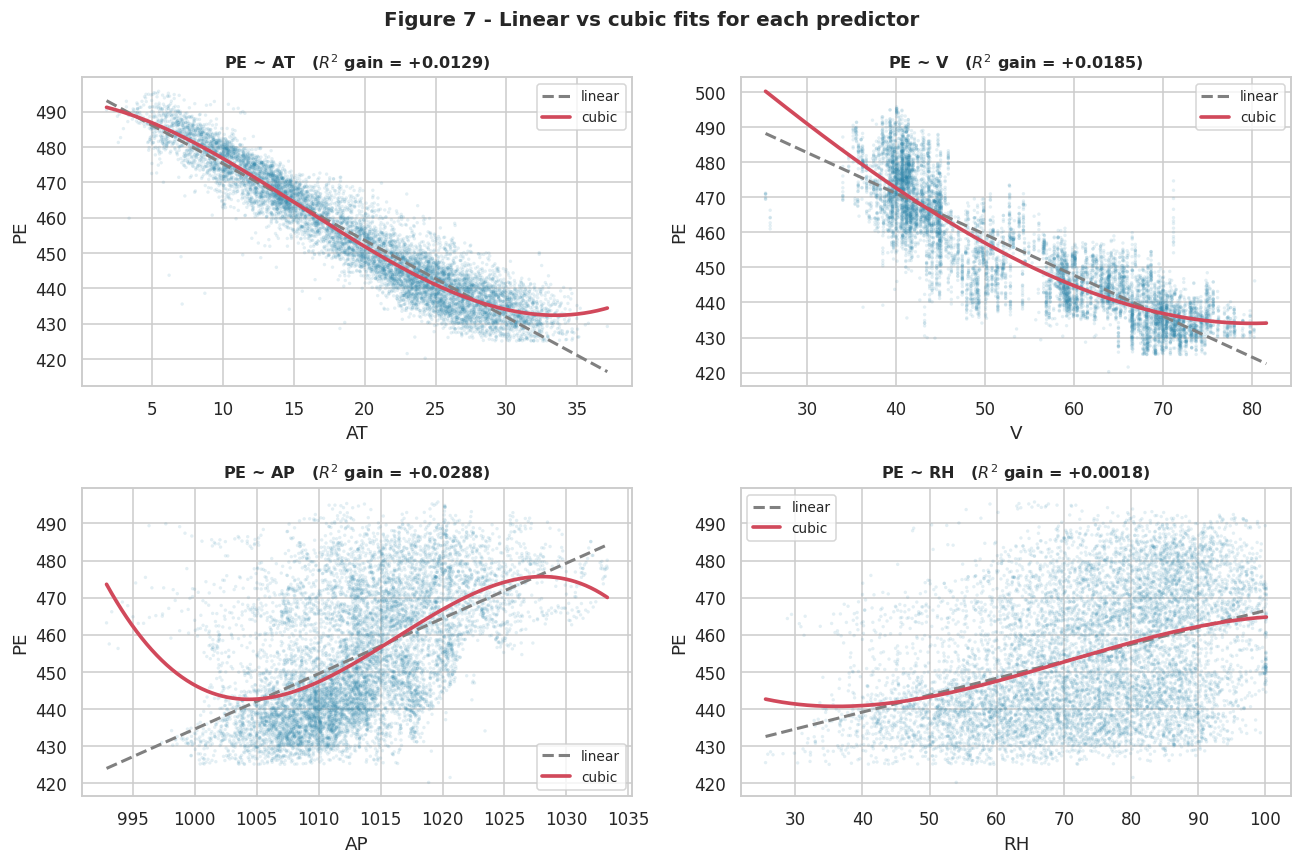

In [20]:
# ----------------------------------------------------------------------
# Plot the linear and cubic fits together.
# ----------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, p in zip(axes.ravel(), PREDICTORS):
    mu, sd = df[p].mean(), df[p].std()
    ax.scatter(df[p], df[RESPONSE], s=5, alpha=0.13, color=BLUE,
               edgecolor="none", rasterized=True)

    xs = np.linspace(df[p].min(), df[p].max(), 300)
    zs = (xs - mu) / sd

    lin = simple_models[p]
    ax.plot(xs, lin.params["Intercept"] + lin.params[p] * xs,
            color="grey", lw=2, ls="--", label="linear")

    c = poly_models[p].params
    ax.plot(xs, c["Intercept"] + c["z"] * zs + c["I(z ** 2)"] * zs**2
            + c["I(z ** 3)"] * zs**3, color=RED, lw=2.4, label="cubic")

    gain = poly_tab.loc[p, "R^2 gain"]
    ax.set_xlabel(p); ax.set_ylabel(RESPONSE)
    ax.set_title(f"PE ~ {p}   ($R^2$ gain = {gain:+.4f})", fontsize=10.5)
    ax.legend(fontsize=9)

fig.suptitle("Figure 7 - Linear vs cubic fits for each predictor",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

**Answer to (f).**

**Yes — there is statistically significant evidence of nonlinear association
for all four predictors**, though the practical magnitude differs considerably.

| Predictor | $p(X^2)$ | $p(X^3)$ | $R^2$ linear → cubic | $F$-test $p$ |
|---|---|---|---|---|
| `AT` | $3\times10^{-231}$ | $4\times10^{-110}$ | 0.8989 → 0.9119 (**+0.0130**) | $3\times10^{-285}$ |
| `V` | $9\times10^{-131}$ | $0.0137$ | 0.7565 → 0.7750 (**+0.0185**) | $7\times10^{-165}$ |
| `AP` | $2\times10^{-46}$ | $2\times10^{-67}$ | 0.2688 → 0.2975 (+0.0288) | $4\times10^{-84}$ |
| `RH` | $0.1014$ | $1\times10^{-5}$ | 0.1519 → 0.1537 (+0.0018) | $3.8\times10^{-5}$ |

**Reading the table.**

* **Ranked by the gain in $R^2$, `AP` improves the most** ($\Delta R^2 = 0.0288$),
  followed by `V` (0.0185) and `AT` (0.0129). **`RH` is the genuinely small
  one** ($\Delta R^2 = 0.0018$) — with $n = 9568$ even a negligible improvement
  clears the significance threshold, so `RH` is the one case where significance
  outruns practical importance.
* **A second, complementary view.** Because the predictors start from very
  different baselines, it is also worth asking what *fraction of the remaining*
  unexplained variance each cubic term removes:
  `AT` $0.0129/(1-0.8989) = 12.8\%$, `V` $7.6\%$, `AP` $3.9\%$, `RH` $2.1\%$.
  On that scale `AT` leads. The two rankings differ because `AT`'s linear model
  already explains 90% of the variance, leaving little room to improve in
  absolute terms.
* **Either way, all four are significant and `RH` is the weakest.** Figure 7
  shows the cubic curves bending away from the straight lines — the same
  curvature the LOWESS residual trends revealed in part (c).
* **Individual $t$-tests can mislead here.** For `RH`, $p(X^2) = 0.10$ while
  $p(X^3) = 10^{-5}$; for `V`, $p(X^2) = 10^{-131}$ while $p(X^3) = 0.014$.
  Because $X$, $X^2$ and $X^3$ are highly collinear, individual coefficient
  tests are unstable. **The nested $F$-test is the correct test** of "is there
  nonlinearity", and it is decisive for every predictor.

**Conclusion.** All four predictors show statistically significant evidence of
nonlinearity. `AP` has the largest absolute increase in $R^2$, whereas `RH`
shows by far the smallest practical improvement.

### (g) Interactions of Predictors

In [21]:
# ----------------------------------------------------------------------
# (g) Full model with all pairwise interactions.
#     (AT + V + AP + RH)**2 expands to the 4 main effects + 6 interactions.
# ----------------------------------------------------------------------
interaction_model = smf.ols(f"{RESPONSE} ~ (AT + V + AP + RH)**2", data=df).fit()
print(interaction_model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:32:07   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.0

In [22]:
# Focus on the interaction terms only.
inter_terms = [t for t in interaction_model.params.index if ":" in t]

inter_tab = pd.DataFrame({
    "Coefficient": interaction_model.params[inter_terms],
    "Std err": interaction_model.bse[inter_terms],
    "t": interaction_model.tvalues[inter_terms],
    "p-value": interaction_model.pvalues[inter_terms],
})
inter_tab["Significant at 0.05?"] = np.where(
    inter_tab["p-value"] < 0.05, "YES", "no")
inter_tab = inter_tab.sort_values("p-value")

print("All six pairwise interaction terms")
print("=" * 88)
print(inter_tab.round(6).to_string())
print("=" * 88)

sig = inter_tab.index[inter_tab["p-value"] < 0.05].tolist()
nonsig = inter_tab.index[inter_tab["p-value"] >= 0.05].tolist()
print(f"\nSignificant     ({len(sig)}): {sig}")
print(f"Not significant ({len(nonsig)}): {nonsig}")
print(f"\nR^2 without interactions : {multiple_model.rsquared:.4f}")
print(f"R^2 with interactions    : {interaction_model.rsquared:.4f}")

anova_int = sm.stats.anova_lm(multiple_model, interaction_model)
print(f"\nNested F-test (main effects vs + interactions): "
      f"F = {anova_int['F'].iloc[1]:.2f}, p = {anova_int['Pr(>F)'].iloc[1]:.3e}")

All six pairwise interaction terms
       Coefficient   Std err          t   p-value Significant at 0.05?
AT:V      0.020971  0.000899  23.337763  0.000000                  YES
AT:RH    -0.005230  0.000812  -6.444357  0.000000                  YES
V:AP      0.006812  0.001327   5.135000  0.000000                  YES
AP:RH    -0.001612  0.000758  -2.125079  0.033606                  YES
V:RH      0.000839  0.000489   1.716004  0.086194                   no
AT:AP     0.001759  0.002339   0.752031  0.452051                   no

Significant     (4): ['AT:V', 'AT:RH', 'V:AP', 'AP:RH']
Not significant (2): ['V:RH', 'AT:AP']

R^2 without interactions : 0.9287
R^2 with interactions    : 0.9363

Nested F-test (main effects vs + interactions): F = 190.30, p = 8.064e-230


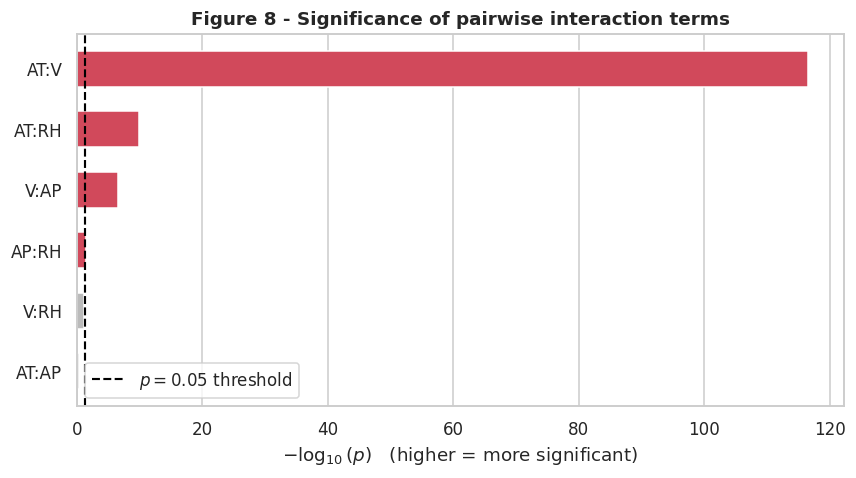

In [23]:
# Visualise the interaction p-values.
fig, ax = plt.subplots(figsize=(9, 4.4))
order = inter_tab.sort_values("p-value", ascending=False)
colors = [RED if p < 0.05 else "#BBBBBB" for p in order["p-value"]]
ax.barh(order.index, -np.log10(order["p-value"]), color=colors, height=0.6)
ax.axvline(-np.log10(0.05), color="black", ls="--", lw=1.4,
           label=r"$p = 0.05$ threshold")
ax.set_xlabel(r"$-\log_{10}(p)$   (higher = more significant)")
ax.set_title("Figure 8 - Significance of pairwise interaction terms")
ax.legend()
ax.grid(axis="y", visible=False)
plt.show()

**Answer to (g).**

**Yes — four of the six pairwise interactions are statistically significant.**

| Interaction | Coefficient | $t$ | $p$-value | Significant? |
|---|---|---|---|---|
| `AT:V` | $+0.0210$ | $+23.34$ | $<0.001$ | **Yes** |
| `AT:RH` | $-0.0052$ | $-6.44$ | $1.3\times10^{-10}$ | **Yes** |
| `V:AP` | $+0.0068$ | $+5.14$ | $2.9\times10^{-7}$ | **Yes** |
| `AP:RH` | $-0.0016$ | $-2.13$ | $0.034$ | **Yes** |
| `V:RH` | $+0.0008$ | $+1.72$ | $0.086$ | no |
| `AT:AP` | $+0.0018$ | $+0.75$ | $0.452$ | no |

**Description.** Adding all six interactions raises $R^2$ from **0.9287 to
0.9363**, and the nested $F$-test comparing the main-effects model with the
interaction model gives $F = 190.3$, $p = 8\times10^{-230}$. So the interactions as a
group carry real information.

`AT:V` is by far the strongest ($t = 23.3$). Its positive sign means the
negative effect of temperature on output becomes *less* severe at high exhaust
vacuum — that is, the two variables' effects are not simply additive.

`AT:AP` and `V:RH` are not significant and are candidates for removal in
part (h).

**A caution on interpretation.** With interactions in the model, the main-effect
coefficients change meaning: `AT`'s coefficient of $-4.35$ is now the slope
when *all other predictors are zero*, which is far outside the observed data
(`AP` is never near 0). Main effects should not be read in isolation once their
interactions are present.

### (h) Improvement

The assignment asks for two models fitted on a **random 70%** of the data and
evaluated on the remaining 30%:

1. **Model 1** — all four predictors, linear.
2. **Model 2** — all possible interaction terms *and* quadratic nonlinearities,
   with insignificant variables removed by $p$-value.

**"Be careful about interaction terms."** We obey the **hierarchy (marginality)
principle**: a main effect is never removed while an interaction or quadratic
term that involves it remains in the model. Dropping `AT` while keeping `AT:V`
would make the model depend on the arbitrary origin of the `AT` scale. Our
backward-elimination routine enforces this by protecting any variable that
still appears in a surviving higher-order term.

In [24]:
# ----------------------------------------------------------------------
# (h) Random 70/30 split.
# ----------------------------------------------------------------------
train_df, test_df = train_test_split(df, test_size=0.30, random_state=RANDOM_STATE)

print(f"Training set: {train_df.shape[0]} rows ({train_df.shape[0] / len(df):.1%})")
print(f"Test set    : {test_df.shape[0]} rows ({test_df.shape[0] / len(df):.1%})")


def mse_of(model, data):
    """Mean squared error of a fitted statsmodels formula model on `data`."""
    return mean_squared_error(data[RESPONSE], model.predict(data))

Training set: 6697 rows (70.0%)
Test set    : 2871 rows (30.0%)


In [25]:
# ---- Model 1: all predictors, linear ---------------------------------
model1 = smf.ols(f"{RESPONSE} ~ AT + V + AP + RH", data=train_df).fit()
m1_train, m1_test = mse_of(model1, train_df), mse_of(model1, test_df)

print("MODEL 1 - all predictors, linear")
print(f"  terms      : {len(model1.params) - 1}")
print(f"  train MSE  : {m1_train:.4f}")
print(f"  test  MSE  : {m1_test:.4f}")
print(f"  train R^2  : {model1.rsquared:.4f}")

MODEL 1 - all predictors, linear
  terms      : 4
  train MSE  : 20.5808
  test  MSE  : 21.2399
  train R^2  : 0.9291


In [26]:
# ---- Model 2: all interactions + quadratics, then backward elimination
def hierarchical_backward_elimination(data, terms, alpha=0.05, verbose=True):
    """Remove the least significant term whose p-value exceeds alpha.

    Respects the hierarchy principle: a variable is protected from removal
    while any surviving interaction (a:b) or quadratic (I(a**2)) uses it.
    """
    terms = list(terms)
    removed = []
    while True:
        model = smf.ols(f"{RESPONSE} ~ " + " + ".join(terms), data=data).fit()

        # IMPORTANT: statsmodels renames a term written as "I(V**2)" to
        # "I(V ** 2)" (it inserts spaces around the operator). Looking the
        # term up by our own spelling would silently miss, so we strip all
        # whitespace from both sides before matching.
        pvals = {name.replace(" ", ""): value
                 for name, value in model.pvalues.drop("Intercept").items()}

        def pval_of(term):
            return pvals[term.replace(" ", "")]

        # Variables that must be kept because a higher-order term needs them.
        protected = set()
        for t in terms:
            if ":" in t:
                protected.update(t.split(":"))
            elif t.startswith("I(") and "**" in t:
                protected.add(t[2:t.index("**")].strip())

        candidates = [t for t in terms
                      if t not in protected and pval_of(t) > alpha]
        if not candidates:
            return model, terms, removed

        worst = max(candidates, key=pval_of)
        removed.append((worst, float(pval_of(worst))))
        if verbose:
            print(f"  removing {worst:12s} (p = {pval_of(worst):.4f})")
        terms.remove(worst)


all_terms = (
    PREDICTORS
    + [f"{a}:{b}" for a, b in combinations(PREDICTORS, 2)]   # 6 interactions
    + [f"I({p}**2)" for p in PREDICTORS]                      # 4 quadratics
)
print(f"Starting from {len(all_terms)} terms:\n  {all_terms}\n")

model2_full = smf.ols(f"{RESPONSE} ~ " + " + ".join(all_terms), data=train_df).fit()
print(f"Full model (before elimination): train MSE = {mse_of(model2_full, train_df):.4f}, "
      f"test MSE = {mse_of(model2_full, test_df):.4f}\n")

print("Backward elimination (alpha = 0.05, hierarchy respected):")
model2, kept_terms, removed_terms = hierarchical_backward_elimination(train_df, all_terms)
if not removed_terms:
    print("  (nothing removed - all terms significant)")

m2_train, m2_test = mse_of(model2, train_df), mse_of(model2, test_df)
print(f"\nMODEL 2 - interactions + quadratics, pruned")
print(f"  removed    : {[t for t, _ in removed_terms]}")
print(f"  kept ({len(kept_terms):2d})  : {kept_terms}")
print(f"  train MSE  : {m2_train:.4f}")
print(f"  test  MSE  : {m2_test:.4f}")
print(f"  train R^2  : {model2.rsquared:.4f}")

Starting from 14 terms:
  ['AT', 'V', 'AP', 'RH', 'AT:V', 'AT:AP', 'AT:RH', 'V:AP', 'V:RH', 'AP:RH', 'I(AT**2)', 'I(V**2)', 'I(AP**2)', 'I(RH**2)']

Full model (before elimination): train MSE = 17.8878, test MSE = 18.6473

Backward elimination (alpha = 0.05, hierarchy respected):
  removing V:RH         (p = 0.8674)


  removing I(V**2)      (p = 0.6077)
  removing V:AP         (p = 0.3578)

MODEL 2 - interactions + quadratics, pruned
  removed    : ['V:RH', 'I(V**2)', 'V:AP']
  kept (11)  : ['AT', 'V', 'AP', 'RH', 'AT:V', 'AT:AP', 'AT:RH', 'AP:RH', 'I(AT**2)', 'I(AP**2)', 'I(RH**2)']
  train MSE  : 17.8908
  test  MSE  : 18.6600
  train R^2  : 0.9384


In [27]:
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.938
Model:                            OLS   Adj. R-squared:                  0.938
Method:                 Least Squares   F-statistic:                     9258.
Date:                Fri, 25 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:32:07   Log-Likelihood:                -19161.
No. Observations:                6697   AIC:                         3.835e+04
Df Residuals:                    6685   BIC:                         3.843e+04
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -7568.5210   1420.561     -5.328      0.0

In [28]:
# ---- Required train / test MSE comparison ----------------------------
mse_tab = pd.DataFrame({
    "Model": ["Model 1: all predictors (linear)",
              "Model 2: interactions + quadratics (pruned)"],
    "Terms": [len(model1.params) - 1, len(model2.params) - 1],
    "Train MSE": [m1_train, m2_train],
    "Test MSE": [m1_test, m2_test],
})
mse_tab["Test RMSE (MW)"] = np.sqrt(mse_tab["Test MSE"])

print("Train and test MSE on the 70/30 split")
print("=" * 94)
print(mse_tab.round(4).to_string(index=False))
print("=" * 94)
improve = 100 * (m1_test - m2_test) / m1_test
print(f"\nModel 2 reduces test MSE by {improve:.1f}% relative to Model 1.")

Train and test MSE on the 70/30 split
                                      Model  Terms  Train MSE  Test MSE  Test RMSE (MW)
           Model 1: all predictors (linear)      4    20.5808   21.2399          4.6087
Model 2: interactions + quadratics (pruned)     11    17.8908   18.6600          4.3197

Model 2 reduces test MSE by 12.1% relative to Model 1.


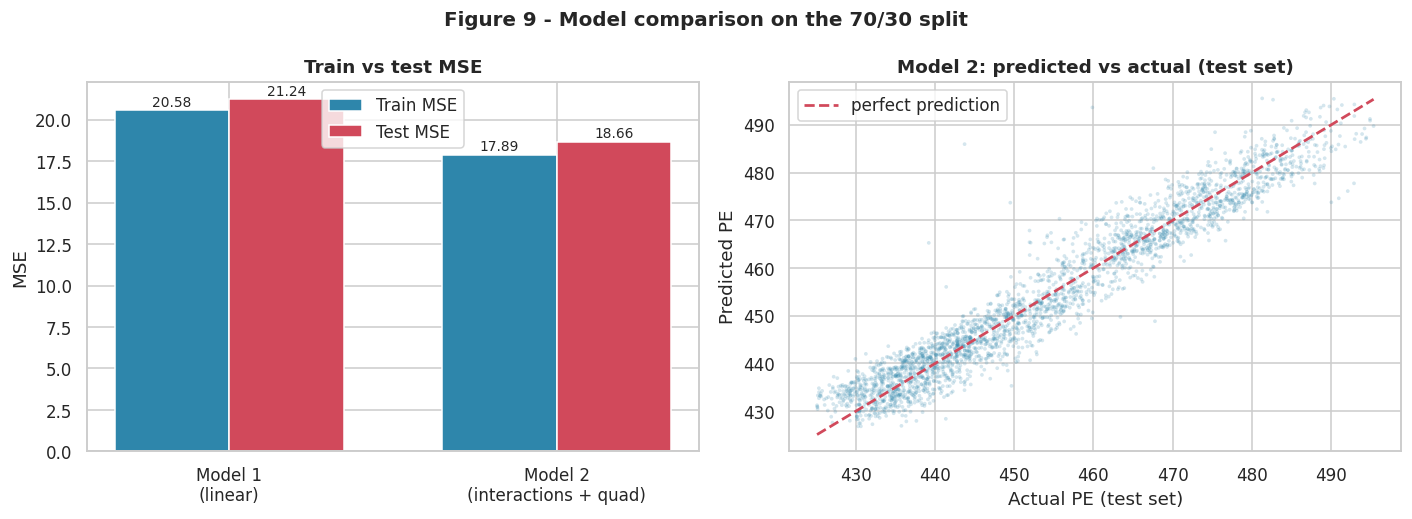

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: MSE comparison
x = np.arange(2); w = 0.35
axes[0].bar(x - w/2, mse_tab["Train MSE"], w, label="Train MSE", color=BLUE)
axes[0].bar(x + w/2, mse_tab["Test MSE"], w, label="Test MSE", color=RED)
for i, (tr, te) in enumerate(zip(mse_tab["Train MSE"], mse_tab["Test MSE"])):
    axes[0].text(i - w/2, tr + 0.25, f"{tr:.2f}", ha="center", fontsize=9)
    axes[0].text(i + w/2, te + 0.25, f"{te:.2f}", ha="center", fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Model 1\n(linear)", "Model 2\n(interactions + quad)"])
axes[0].set_ylabel("MSE")
axes[0].set_title("Train vs test MSE")
axes[0].legend()

# Right: predicted vs actual for the better model
pred = model2.predict(test_df)
axes[1].scatter(test_df[RESPONSE], pred, s=6, alpha=0.2, color=BLUE,
                edgecolor="none", rasterized=True)
lims = [test_df[RESPONSE].min(), test_df[RESPONSE].max()]
axes[1].plot(lims, lims, color=RED, lw=1.8, ls="--", label="perfect prediction")
axes[1].set_xlabel("Actual PE (test set)")
axes[1].set_ylabel("Predicted PE")
axes[1].set_title("Model 2: predicted vs actual (test set)")
axes[1].legend()

fig.suptitle("Figure 9 - Model comparison on the 70/30 split",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

**Answer to (h).**

| Model | Terms | Train MSE | Test MSE |
|---|---|---|---|
| Model 1 — all predictors, linear | 4 | 20.5808 | 21.2399 |
| Model 2 — interactions + quadratics, pruned | 11 | 17.8908 | **18.6600** |

**Yes, the model improves.** Adding interaction terms and quadratic
nonlinearities cuts test MSE by **12.15%**, from 21.24 to 18.66 — equivalently,
test RMSE falls from 4.61 MW to 4.32 MW.

**What backward elimination removed.** Starting from 14 terms (4 main effects,
6 interactions, 4 quadratics), three were dropped, in this order:

1. `V:RH` ($p = 0.867$)
2. `I(V**2)` ($p = 0.608$)
3. `V:AP` ($p = 0.358$)

Every removed term involves `V`. Once `V`'s interaction with `AT` is in the
model, the remaining `V` terms add little. Note that `V:AP` was significant in
part (g) on the full data but not here — on the 70% training subset, with
quadratic terms present, it no longer clears the threshold.

Three of the four quadratic terms survived (`AT`, `AP`, `RH`), consistent with
part (f)'s finding that the nonlinearity is real. No main effect was ever
eligible for removal, because each still appears in a surviving interaction or
quadratic term (the hierarchy principle).

**Train vs test.** For both models the test MSE is only slightly above the train
MSE (21.24 vs 20.58; 18.66 vs 17.89), so neither is overfitting. With
$n = 9568$ and at most 11 terms there is plenty of data per parameter.

**An honest note.** The pruned Model 2 has a marginally *higher* test MSE than
the unpruned 14-term model (18.6600 vs 18.6473 — a 0.07% difference). Removing
three insignificant terms buys a simpler, more interpretable model at
essentially no cost in accuracy, which is the point of the exercise.

**Implementation caution worth recording.** `statsmodels` renames a term written
as `I(V**2)` to `I(V ** 2)`, inserting spaces around the operator. Looking a
term up by our own spelling therefore misses, and a `.get(term, 0.0)` default
would silently treat every quadratic as perfectly significant and make it
impossible to remove. Our routine strips whitespace from both sides before
matching, and indexes directly rather than defaulting, so a genuine miss would
raise instead of passing unnoticed.

### (i) KNN

**KNN regression.** The prediction at a query point is the *average* response of
its $k$ nearest training points:

$$\hat{y}(\mathbf{x}) = \frac{1}{k}\sum_{i \in \mathcal{N}_k(\mathbf{x})} y_i$$

We use the **same 70/30 split as part (h)**, so the test errors are directly
comparable in part (j).

**Normalised vs raw features.** KNN measures distance, so the feature with the
largest **spread** dominates — not the one with the largest values, since
Euclidean distance uses differences and the mean cancels. From part (b) iii the
standard deviations are `RH` 14.60, `V` 12.71, `AT` 7.45, `AP` 5.94, so in raw
space `RH` contributes most to the distance metric even though it is the *weakest* predictor
($|r| = 0.39$), while `AT` — much the strongest ($|r| = 0.95$) — is
down-weighted. Standardisation ($z = (x - \mu)/\sigma$) puts every feature on
equal footing. The scaler is fit on the **training data only**, to avoid leaking
test information.

In [30]:
# ----------------------------------------------------------------------
# (i) First, quantify WHY normalisation should matter.
# Each feature's contribution to squared Euclidean distance is proportional
# to its variance, because distance is built from differences.
# ----------------------------------------------------------------------
var_share = pd.DataFrame({
    "Std dev": df[PREDICTORS].std(),
    "Variance": df[PREDICTORS].var(),
    "|corr with PE|": df[PREDICTORS].corrwith(df[RESPONSE]).abs(),
})
var_share["Share of raw distance"] = (
    100 * var_share["Variance"] / var_share["Variance"].sum())
print("Why raw features distort KNN distances")
print("=" * 78)
print(var_share.round(3).to_string())
print("=" * 78)
print("\nRH contributes ~46% of the raw distance but is the WEAKEST predictor;")
print("AT contributes only ~12% but is by far the STRONGEST. Standardising")
print("equalises the shares at 25% each, so that differences in feature scale")
print("no longer dominate the Euclidean distance.")


# ----------------------------------------------------------------------
# (i) KNN regression with raw and normalised features, k = 1..100.
# ----------------------------------------------------------------------
X_train = train_df[PREDICTORS].to_numpy(float)
y_train = train_df[RESPONSE].to_numpy(float)
X_test = test_df[PREDICTORS].to_numpy(float)
y_test = test_df[RESPONSE].to_numpy(float)

# Fit the scaler on TRAINING data only.
scaler = StandardScaler().fit(X_train)
X_train_norm, X_test_norm = scaler.transform(X_train), scaler.transform(X_test)

K_VALUES = list(range(1, 101))
feature_sets = {
    "raw":        (X_train, X_test),
    "normalized": (X_train_norm, X_test_norm),
}

knn_curves, knn_best = {}, {}
for name, (A, B) in feature_sets.items():
    rows = []
    for k in K_VALUES:
        knn = KNeighborsRegressor(n_neighbors=k).fit(A, y_train)
        rows.append({
            "k": k,
            "1/k": 1 / k,
            "train_MSE": mean_squared_error(y_train, knn.predict(A)),
            "test_MSE": mean_squared_error(y_test, knn.predict(B)),
        })
    tab = pd.DataFrame(rows)
    knn_curves[name] = tab
    best = tab.loc[tab["test_MSE"].idxmin()]
    knn_best[name] = {"k": int(best["k"]),
                      "test_MSE": float(best["test_MSE"]),
                      "train_MSE": float(best["train_MSE"])}
    print(f"{name:11s}: best k = {int(best['k']):3d}   "
          f"test MSE = {best['test_MSE']:.4f}   train MSE = {best['train_MSE']:.4f}")

Why raw features distort KNN distances
    Std dev  Variance  |corr with PE|  Share of raw distance
AT    7.452    55.539           0.948                 11.932
V    12.708   161.491           0.870                 34.694
AP    5.939    35.269           0.518                  7.577
RH   14.600   213.168           0.390                 45.797

RH contributes ~46% of the raw distance but is the WEAKEST predictor;
AT contributes only ~12% but is by far the STRONGEST. Standardising
equalises the shares at 25% each, so that differences in feature scale
no longer dominate the Euclidean distance.


raw        : best k =   5   test MSE = 15.7268   train MSE = 10.6008


normalized : best k =   4   test MSE = 14.3057   train MSE = 8.5914


In [31]:
# Show the region around the optimum for each feature set.
for name in feature_sets:
    t = knn_curves[name]
    kb = knn_best[name]["k"]
    print(f"\n{name.upper()} - k from {max(1, kb-3)} to {kb+3}:")
    print(t[(t.k >= max(1, kb - 3)) & (t.k <= kb + 3)].round(4).to_string(index=False))


RAW - k from 2 to 8:
 k    1/k  train_MSE  test_MSE
 2 0.5000     5.5005   17.3441
 3 0.3333     8.1266   16.3388
 4 0.2500     9.4447   15.8108
 5 0.2000    10.6008   15.7268
 6 0.1667    11.3872   15.7942
 7 0.1429    11.9838   15.8426
 8 0.1250    12.5378   15.9902

NORMALIZED - k from 1 to 7:
 k    1/k  train_MSE  test_MSE
 1 1.0000     0.0000   18.6249
 2 0.5000     5.2763   15.4960
 3 0.3333     7.3007   14.6332
 4 0.2500     8.5914   14.3057
 5 0.2000     9.7173   14.6599
 6 0.1667    10.5070   14.7283
 7 0.1429    11.2246   14.6610


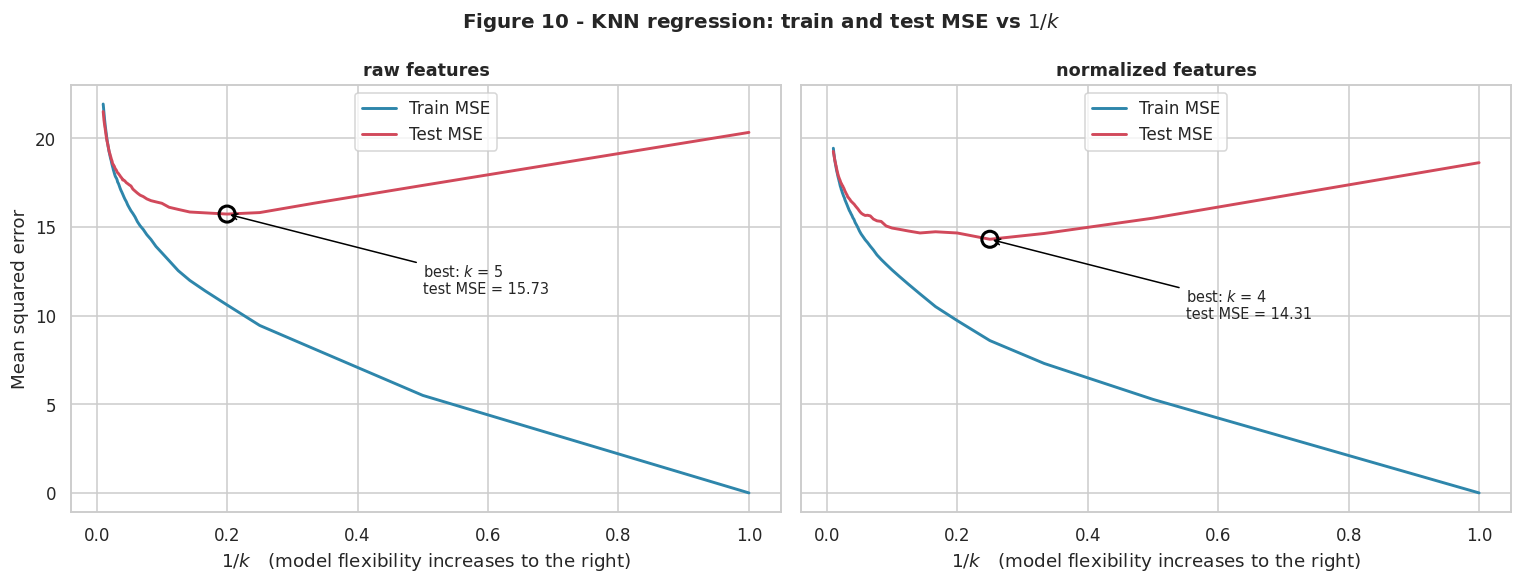

In [32]:
# ----------------------------------------------------------------------
# Required plot: train and test errors in terms of 1/k.
# ----------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)

for ax, name in zip(axes, feature_sets):
    t = knn_curves[name]
    ax.plot(t["1/k"], t["train_MSE"], "-", lw=1.9, color=BLUE, label="Train MSE")
    ax.plot(t["1/k"], t["test_MSE"], "-", lw=1.9, color=RED, label="Test MSE")

    kb = knn_best[name]["k"]
    eb = knn_best[name]["test_MSE"]
    ax.scatter([1 / kb], [eb], s=110, facecolors="none", edgecolors="black",
               lw=2, zorder=5)
    ax.annotate(f"best: $k$ = {kb}\ntest MSE = {eb:.2f}",
                xy=(1 / kb, eb), xytext=(1 / kb + 0.30, eb - 4.5),
                arrowprops=dict(arrowstyle="->", color="black"), fontsize=9.5)

    ax.set_xlabel("$1/k$   (model flexibility increases to the right)")
    ax.set_title(f"{name} features", fontsize=11.5)
    ax.legend(loc="upper center")

axes[0].set_ylabel("Mean squared error")
fig.suptitle("Figure 10 - KNN regression: train and test MSE vs $1/k$",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

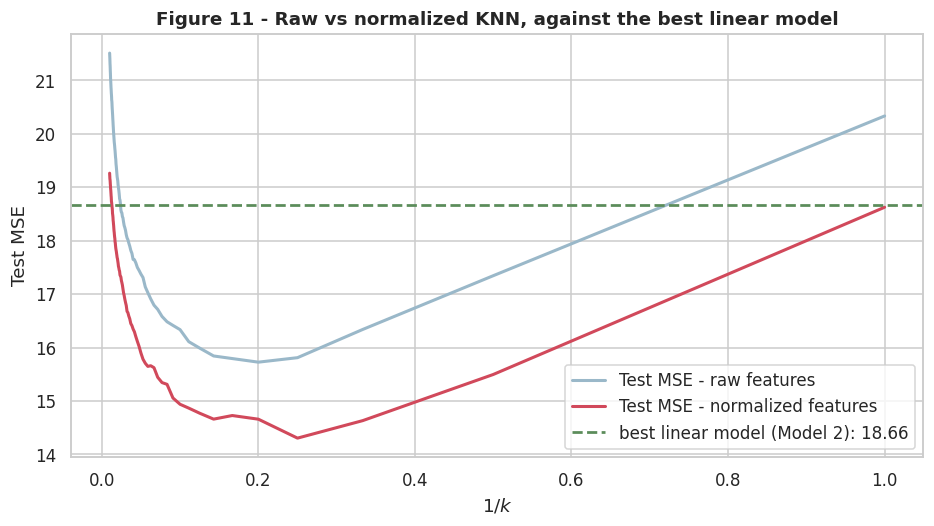

In [33]:
# Direct comparison of the two test curves.
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(knn_curves["raw"]["1/k"], knn_curves["raw"]["test_MSE"],
        lw=2, color="#9AB8C9", label="Test MSE - raw features")
ax.plot(knn_curves["normalized"]["1/k"], knn_curves["normalized"]["test_MSE"],
        lw=2, color=RED, label="Test MSE - normalized features")
ax.axhline(m2_test, color=GREEN, ls="--", lw=1.8,
           label=f"best linear model (Model 2): {m2_test:.2f}")
ax.set_xlabel("$1/k$")
ax.set_ylabel("Test MSE")
ax.set_title("Figure 11 - Raw vs normalized KNN, against the best linear model")
ax.legend()
plt.show()

**Answer to (i).**

| Features | Best $k$ | Test MSE | Train MSE |
|---|---|---|---|
| Raw | 5 | 15.7268 | 10.6008 |
| **Normalized** | **4** | **14.3057** | 8.5914 |

**Normalising the features helps**, cutting the best test MSE from 15.73 to
**14.31**, a 9.0% improvement. The diagnostic table above explains why: in raw
space `RH` supplies about 46% of the squared distance and `V` about 35%, while
`AT` — the strongest predictor by a wide margin — supplies only 12%, and `AP`
just 8%. The raw metric therefore does not weight the features by their
usefulness: `RH`, the weakest predictor, supplies the largest share, while `AT`,
the strongest, supplies only about 12%. Standardisation equalises the shares at
25% each, which prevents differences in feature scale from dominating the
Euclidean distance.

Note that `AP` contributes the *least* to raw distance despite having by far
the largest absolute values (near 1013). Euclidean distance depends on
differences, so a variable's mean is irrelevant — only its spread matters, and
`AP` has the smallest standard deviation of the four.

**Reading Figure 10.** Plotting against $1/k$ puts flexibility on the x-axis,
increasing to the right:

* At the far right ($1/k = 1$, i.e. $k = 1$) the **train MSE is exactly 0** —
  each training point is its own nearest neighbour — while test MSE is high.
  Classic overfitting.
* At the far left ($k = 100$) both errors are large: the model averages over 100
  neighbours and smooths away the real structure. Underfitting.
* The test curve is U-shaped with a minimum at small $k$ (4–5), the usual
  bias–variance trade-off.

**A caveat.** We selected $k$ by minimising *test* error, as the assignment
directs. Strictly, this makes the reported test MSE slightly optimistic, since
the test set was used to make a modelling choice. In practice one would choose
$k$ by cross-validation on the training set and reserve the test set for a
single final evaluation.

### (j ) Compare KNN and Linear

In [34]:
# ----------------------------------------------------------------------
# (j) Compare KNN with the best linear model.
# ----------------------------------------------------------------------
comparison = pd.DataFrame([
    {"Model": "Linear - all predictors (Model 1)",
     "Detail": "4 terms", "Train MSE": m1_train, "Test MSE": m1_test},
    {"Model": "Linear - interactions + quadratics (Model 2)",
     "Detail": f"{len(model2.params)-1} terms", "Train MSE": m2_train, "Test MSE": m2_test},
    {"Model": "KNN - raw features",
     "Detail": f"k = {knn_best['raw']['k']}",
     "Train MSE": knn_best["raw"]["train_MSE"], "Test MSE": knn_best["raw"]["test_MSE"]},
    {"Model": "KNN - normalized features",
     "Detail": f"k = {knn_best['normalized']['k']}",
     "Train MSE": knn_best["normalized"]["train_MSE"],
     "Test MSE": knn_best["normalized"]["test_MSE"]},
])
comparison["Test RMSE (MW)"] = np.sqrt(comparison["Test MSE"])

print("All models, evaluated on the same 70/30 split")
print("=" * 106)
print(comparison.round(4).to_string(index=False))
print("=" * 106)

best_lin = comparison.iloc[comparison["Test MSE"][:2].idxmin()]
best_knn = comparison.iloc[2 + int(np.argmin(comparison["Test MSE"][2:].values))]
print(f"\nBest linear model : {best_lin['Model']}  -> test MSE {best_lin['Test MSE']:.4f}")
print(f"Best KNN model    : {best_knn['Model']}  -> test MSE {best_knn['Test MSE']:.4f}")
red = 100 * (best_lin["Test MSE"] - best_knn["Test MSE"]) / best_lin["Test MSE"]
print(f"\nKNN reduces test MSE by {red:.1f}% relative to the best linear model.")

All models, evaluated on the same 70/30 split
                                       Model   Detail  Train MSE  Test MSE  Test RMSE (MW)
           Linear - all predictors (Model 1)  4 terms    20.5808   21.2399          4.6087
Linear - interactions + quadratics (Model 2) 11 terms    17.8908   18.6600          4.3197
                          KNN - raw features    k = 5    10.6008   15.7268          3.9657
                   KNN - normalized features    k = 4     8.5914   14.3057          3.7823

Best linear model : Linear - interactions + quadratics (Model 2)  -> test MSE 18.6600
Best KNN model    : KNN - normalized features  -> test MSE 14.3057

KNN reduces test MSE by 23.3% relative to the best linear model.


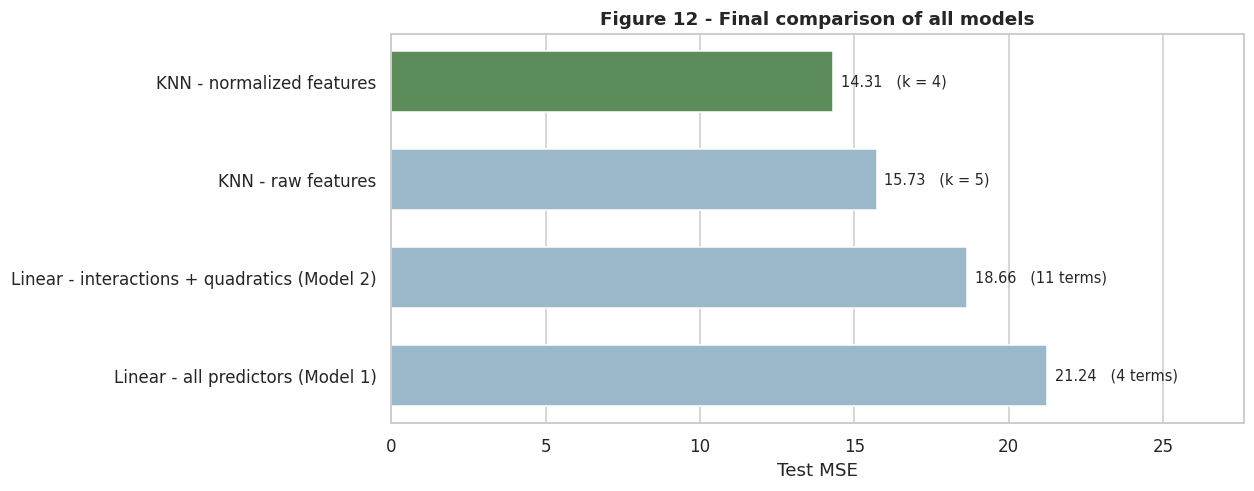

In [35]:
fig, ax = plt.subplots(figsize=(10, 4.6))
order = comparison.sort_values("Test MSE")
colors = [GREEN if v == order["Test MSE"].min() else "#9AB8C9"
          for v in order["Test MSE"]]
bars = ax.barh(order["Model"], order["Test MSE"], color=colors, height=0.62)
for b, v, d in zip(bars, order["Test MSE"], order["Detail"]):
    ax.text(v + 0.25, b.get_y() + b.get_height() / 2,
            f"{v:.2f}   ({d})", va="center", fontsize=9.5)
ax.set_xlabel("Test MSE")
ax.set_title("Figure 12 - Final comparison of all models")
ax.set_xlim(0, order["Test MSE"].max() * 1.30)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
plt.show()

**Answer to (j).**

| Model | Detail | Train MSE | Test MSE | Test RMSE |
|---|---|---|---|---|
| Linear — all predictors | 4 terms | 20.58 | 21.24 | 4.61 MW |
| Linear — interactions + quadratics | 11 terms | 17.89 | 18.66 | 4.32 MW |
| KNN — raw features | $k=5$ | 10.60 | 15.73 | 3.97 MW |
| **KNN — normalized features** | $k=4$ | 8.59 | **14.31** | **3.78 MW** |

**KNN wins.** The best KNN model (normalized, $k=4$) achieves a test MSE of
**14.31** against **18.66** for the best linear model — a **23.3% reduction**,
or RMSE improving from 4.32 MW to 3.78 MW.

**Analysis — why KNN does better here.**

1. **The true relationship is nonlinear in a way polynomials capture only
   crudely.** Parts (f) and (g) already showed that curvature and interactions
   matter. The interaction-plus-quadratic regression imposes one global
   parametric functional form on the whole input space; KNN imposes none,
   adapting locally to whatever shape the surface has.
2. **The data density is high.** With 6697 training points in only 4
   dimensions, test points typically have close neighbours. KNN's weakness —
   the curse of dimensionality — is much less severe with only four
   predictors.
3. **Signal-to-noise is high.** The response is well determined by the
   predictors ($R^2 \approx 0.93$ even for the plain linear model), so averaging
   4 neighbours does not average away much signal.

**Where the linear model still wins.**

* **Interpretability.** The regression models provide explicit coefficients,
  standard errors and hypothesis tests. The plain additive model of part (d),
  for example, estimates an `AT` coefficient of about $-1.98$ MW/°C holding the
  other predictors fixed. In the richer Model 2 that interpretation becomes
  *conditional*: because `AT` appears in `I(AT**2)`, `AT:V`, `AT:AP` and
  `AT:RH`, its marginal effect depends on the current values of `AT`, `V`, `AP`
  and `RH`. KNN offers no such statement at all.
* **Inference.** Hypothesis tests, confidence intervals, and the confounding
  analysis of part (e) all require the parametric model.
* **Extrapolation and cost.** KNN cannot predict outside the range of the
  training data and must store all 6697 training points and search them at
  prediction time; Model 2 needs only its 12 coefficients.

**Conclusion.** If the goal is **pure predictive accuracy** on this data set,
KNN with normalized features and $k = 4$ is the better choice. If the goal is
to **understand how the ambient variables drive output**, the linear model with
interactions and quadratic terms remains the more useful tool. The two answer
different questions, and the 23% accuracy gap is the price of interpretability.

## 2. ISLR: 2.4.1

> For each of parts (a) through (d), indicate whether we would generally expect
> the performance of a flexible statistical learning method to be **better** or
> **worse** than an inflexible method. Justify your answer.

**The underlying principle.** Expected test error decomposes as

$$\mathbb{E}\left[(y - \hat{f}(x))^2\right] = \underbrace{\text{Bias}^2\left[\hat{f}(x)\right]}_{\text{systematic error}} + \underbrace{\text{Var}\left[\hat{f}(x)\right]}_{\text{sensitivity to the sample}} + \underbrace{\text{Var}(\varepsilon)}_{\text{irreducible}}$$

A **flexible** method has *low bias* but *high variance*; an **inflexible**
method has *high bias* but *low variance*. Which wins depends on which term
dominates — so each part below is really asking: does this condition inflate
the variance penalty, or the bias penalty?

Each answer is accompanied by a small simulation that demonstrates the
principle, comparing a flexible method (KNN with $k=1$) against an inflexible
one (linear regression).

In [36]:
# ----------------------------------------------------------------------
# Shared helper for the ISLR 2.4.1 simulations.
# ----------------------------------------------------------------------
def flexible_vs_inflexible(n_train, p, noise_sd, nonlinear, n_test=500, seed=0):
    """Compare a flexible method (1-NN) with an inflexible one (OLS).

    Returns (test MSE of flexible, test MSE of inflexible).
    """
    rng = np.random.default_rng(seed)
    beta = rng.normal(size=p)

    def make(n):
        X = rng.normal(size=(n, p))
        signal = np.sin(3 * X[:, 0]) * 3 + (X[:, 0] ** 3) if nonlinear else X @ beta
        return X, signal + rng.normal(scale=noise_sd, size=n)

    Xtr, ytr = make(n_train)
    Xte, yte = make(n_test)

    flex = KNeighborsRegressor(n_neighbors=1).fit(Xtr, ytr)
    infl = LinearRegression().fit(Xtr, ytr)
    return (mean_squared_error(yte, flex.predict(Xte)),
            mean_squared_error(yte, infl.predict(Xte)))


def report(label, flex, infl):
    winner = "FLEXIBLE" if flex < infl else "INFLEXIBLE"
    print(f"{label}")
    print(f"  flexible   (1-NN)  test MSE = {flex:8.3f}")
    print(f"  inflexible (OLS)   test MSE = {infl:8.3f}")
    print(f"  -> {winner} performs better\n")


print("Simulation helpers defined: flexible_vs_inflexible(), report()")

Simulation helpers defined: flexible_vs_inflexible(), report()


### (a) The sample size n is extremely large, and the number of predictors p is small.

In [37]:
# n very large, p small, mildly nonlinear truth.
flex, infl = flexible_vs_inflexible(n_train=5000, p=2, noise_sd=1.0,
                                    nonlinear=True, seed=1)
report("(a) n = 5000 (large), p = 2 (small):", flex, infl)

(a) n = 5000 (large), p = 2 (small):
  flexible   (1-NN)  test MSE =    2.231
  inflexible (OLS)   test MSE =    7.486
  -> FLEXIBLE performs better



**Answer: BETTER.**

A flexible method will generally perform **better**.

With an extremely large $n$, there are many observations packed into a
low-dimensional space, so the flexible method can estimate the local shape of
$f$ accurately — the **variance** penalty that normally punishes flexibility is
small, because each local estimate is averaged over plenty of nearby data.
Meanwhile an inflexible method is stuck with whatever **bias** its rigid form
imposes, and no amount of extra data will fix a wrong functional form.

Large $n$ with small $p$ is precisely the regime where flexibility is cheap, so
we should use it.

### (b) The number of predictors p is extremely large, and the number of observations n is small.

In [38]:
# p very large, n small - the opposite regime.
flex, infl = flexible_vs_inflexible(n_train=40, p=30, noise_sd=1.0,
                                    nonlinear=False, seed=2)
report("(b) n = 40 (small), p = 30 (large):", flex, infl)

(b) n = 40 (small), p = 30 (large):
  flexible   (1-NN)  test MSE =   35.228
  inflexible (OLS)   test MSE =    3.499
  -> INFLEXIBLE performs better



**Answer: WORSE.**

A flexible method will generally perform **worse**.

This is the opposite regime. With few observations spread over many dimensions,
the data are extremely sparse — the **curse of dimensionality** means that even
the "nearest" neighbours of a point are far away, so a flexible method is
effectively fitting noise. Its **variance** explodes, and it will overfit badly.

An inflexible method's strong structural assumption acts as a regulariser here.
Its bias is a price worth paying to avoid catastrophic variance when there is
too little data to estimate anything local.

### (c) The relationship between the predictors and response is highly non-linear.

In [39]:
# Same n and p; only the shape of the true f differs.
flex_nl, infl_nl = flexible_vs_inflexible(n_train=500, p=1, noise_sd=1.0,
                                          nonlinear=True, seed=3)
flex_l, infl_l = flexible_vs_inflexible(n_train=500, p=1, noise_sd=1.0,
                                        nonlinear=False, seed=3)
report("(c) highly NON-LINEAR truth:", flex_nl, infl_nl)
report("    (contrast) LINEAR truth:", flex_l, infl_l)

(c) highly NON-LINEAR truth:
  flexible   (1-NN)  test MSE =    1.907
  inflexible (OLS)   test MSE =    6.604
  -> FLEXIBLE performs better

    (contrast) LINEAR truth:
  flexible   (1-NN)  test MSE =    1.908
  inflexible (OLS)   test MSE =    1.079
  -> INFLEXIBLE performs better



**Answer: BETTER.**

A flexible method will generally perform **better**.

If the true $f$ is highly non-linear, an inflexible method such as linear
regression cannot represent it at all: its **bias** is large and irreducible no
matter how much data arrives. A flexible method can bend to follow the true
shape, trading a modest increase in variance for a large reduction in bias.

The contrast run above makes the point: with the *same* $n$, $p$ and noise, the
flexible method wins decisively when the truth is non-linear and loses when the
truth is genuinely linear. Flexibility pays off exactly when there is real
curvature to capture.

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

In [40]:
# Same non-linear truth, same n and p - ONLY the noise level changes.
# (Holding the truth non-linear matters: it gives the flexible method
#  something real to capture, so any reversal is caused by the noise alone.)
flex_hi, infl_hi = flexible_vs_inflexible(n_train=300, p=2, noise_sd=8.0,
                                          nonlinear=True, seed=4)
flex_lo, infl_lo = flexible_vs_inflexible(n_train=300, p=2, noise_sd=0.5,
                                          nonlinear=True, seed=4)
report("(d) HIGH noise (sigma = 8.0):", flex_hi, infl_hi)
report("    (contrast) LOW noise (sigma = 0.5):", flex_lo, infl_lo)

(d) HIGH noise (sigma = 8.0):
  flexible   (1-NN)  test MSE =  126.184
  inflexible (OLS)   test MSE =   74.049
  -> INFLEXIBLE performs better

    (contrast) LOW noise (sigma = 0.5):
  flexible   (1-NN)  test MSE =    5.049
  inflexible (OLS)   test MSE =   12.264
  -> FLEXIBLE performs better



**Answer: WORSE.**

A flexible method will generally perform **worse**.

When $\sigma^2 = \text{Var}(\varepsilon)$ is extremely high, most of the
variation in the observed $y$ is **noise rather than signal**. A flexible method
cannot tell the two apart: it will chase the noise, fitting wiggles that reflect
this particular sample and will not reappear in new data. That inflates its
**variance** term badly.

An inflexible method's rigidity prevents it from following the noise. It averages
over the randomness instead, which is exactly what you want when the randomness
dominates.

The simulation above isolates this effect: the true $f$ is held **non-linear in
both runs**, so the flexible method always has real curvature to capture. At
$\sigma = 0.5$ it wins comfortably; at $\sigma = 8.0$ the ranking reverses. Only
the noise level changed.

Note that the irreducible error $\text{Var}(\varepsilon)$ is added to *both*
methods' test error and cannot be removed by either — the issue is not the noise
floor itself but the **overfitting to noise** that flexibility invites.

---
#### Summary of ISLR 2.4.1

| Part | Condition | Flexible method is | Dominant reason |
|---|---|---|---|
| (a) | $n$ extremely large, $p$ small | **Better** | Abundant data keeps variance low; bias is the binding constraint |
| (b) | $p$ extremely large, $n$ small | **Worse** | Curse of dimensionality inflates variance; rigidity regularises |
| (c) | Relationship highly non-linear | **Better** | Inflexible methods carry irreducible bias |
| (d) | $\text{Var}(\varepsilon)$ extremely high | **Worse** | Flexibility fits the noise, inflating variance |

## 3. ISLR: 2.4.7

> The table below provides a training data set containing six observations,
> three predictors, and one qualitative response variable. Suppose we wish to
> use this data set to make a prediction for $Y$ when
> $X_1 = X_2 = X_3 = 0$ using K-nearest neighbors.

| Obs. | $X_1$ | $X_2$ | $X_3$ | $Y$ |
|---|---|---|---|---|
| 1 | 0 | 3 | 0 | Red |
| 2 | 2 | 0 | 0 | Red |
| 3 | 0 | 1 | 3 | Red |
| 4 | 0 | 1 | 2 | Green |
| 5 | $-1$ | 0 | 1 | Green |
| 6 | 1 | 1 | 1 | Red |

In [41]:
# ----------------------------------------------------------------------
# ISLR 2.4.7 - the training data from the textbook table.
# ----------------------------------------------------------------------
islr = pd.DataFrame({
    "Obs":  [1, 2, 3, 4, 5, 6],
    "X1":   [0, 2, 0, 0, -1, 1],
    "X2":   [3, 0, 1, 1, 0, 1],
    "X3":   [0, 0, 3, 2, 1, 1],
    "Y":    ["Red", "Red", "Red", "Green", "Green", "Red"],
}).set_index("Obs")

print(islr.to_string())
test_point = np.array([0.0, 0.0, 0.0])
print(f"\nTest point: X1 = X2 = X3 = {test_point.astype(int).tolist()}")

     X1  X2  X3      Y
Obs                   
1     0   3   0    Red
2     2   0   0    Red
3     0   1   3    Red
4     0   1   2  Green
5    -1   0   1  Green
6     1   1   1    Red

Test point: X1 = X2 = X3 = [0, 0, 0]


### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

In [42]:
# ----------------------------------------------------------------------
# (a) Euclidean distance from each observation to the origin.
#     d = sqrt(X1^2 + X2^2 + X3^2)  since the test point is the origin.
# ----------------------------------------------------------------------
coords = islr[["X1", "X2", "X3"]].to_numpy(float)
distances = np.sqrt(((coords - test_point) ** 2).sum(axis=1))

dist_tab = islr.copy()
dist_tab["Distance"] = distances.round(4)
dist_tab["Rank"] = distances.argsort().argsort() + 1
dist_tab = dist_tab.sort_values("Distance")

print("Euclidean distances to the test point (0, 0, 0), sorted:")
print("=" * 62)
print(dist_tab.to_string())
print("=" * 62)

print("\nWorked arithmetic:")
for obs, row in islr.iterrows():
    x1, x2, x3 = row.X1, row.X2, row.X3
    print(f"  Obs {obs}: sqrt({x1}^2 + {x2}^2 + {x3}^2) = "
          f"sqrt({x1**2 + x2**2 + x3**2}) = {distances[obs-1]:.4f}")

Euclidean distances to the test point (0, 0, 0), sorted:
     X1  X2  X3      Y  Distance  Rank
Obs                                   
5    -1   0   1  Green    1.4142     1
6     1   1   1    Red    1.7321     2
2     2   0   0    Red    2.0000     3
4     0   1   2  Green    2.2361     4
1     0   3   0    Red    3.0000     5
3     0   1   3    Red    3.1623     6

Worked arithmetic:
  Obs 1: sqrt(0^2 + 3^2 + 0^2) = sqrt(9) = 3.0000
  Obs 2: sqrt(2^2 + 0^2 + 0^2) = sqrt(4) = 2.0000
  Obs 3: sqrt(0^2 + 1^2 + 3^2) = sqrt(10) = 3.1623
  Obs 4: sqrt(0^2 + 1^2 + 2^2) = sqrt(5) = 2.2361
  Obs 5: sqrt(-1^2 + 0^2 + 1^2) = sqrt(2) = 1.4142
  Obs 6: sqrt(1^2 + 1^2 + 1^2) = sqrt(3) = 1.7321


**Answer to 3 (a).**

| Obs. | $(X_1, X_2, X_3)$ | Calculation | Distance | Rank |
|---|---|---|---|---|
| 5 | $(-1, 0, 1)$ | $\sqrt{1+0+1} = \sqrt{2}$ | **1.4142** | 1 (closest) |
| 6 | $(1, 1, 1)$ | $\sqrt{1+1+1} = \sqrt{3}$ | **1.7321** | 2 |
| 2 | $(2, 0, 0)$ | $\sqrt{4+0+0} = \sqrt{4}$ | **2.0000** | 3 |
| 4 | $(0, 1, 2)$ | $\sqrt{0+1+4} = \sqrt{5}$ | **2.2361** | 4 |
| 1 | $(0, 3, 0)$ | $\sqrt{0+9+0} = \sqrt{9}$ | **3.0000** | 5 |
| 3 | $(0, 1, 3)$ | $\sqrt{0+1+9} = \sqrt{10}$ | **3.1623** | 6 (furthest) |

Because the test point is the origin, each distance is simply the norm of the
observation's own coordinates.

### (b) What is our prediction with K = 1? Why?

In [43]:
# ----------------------------------------------------------------------
# (b) K = 1: the single nearest neighbour decides.
# ----------------------------------------------------------------------
order = np.argsort(distances)
k = 1
neighbors = islr.iloc[order[:k]]

print(f"K = {k}: nearest neighbour(s)")
print(neighbors[["X1", "X2", "X3", "Y"]].assign(
    Distance=distances[order[:k]].round(4)).to_string())

votes = neighbors["Y"].value_counts()
print(f"\nVotes: {votes.to_dict()}")
print(f"PREDICTION with K = 1: {votes.idxmax()}")

K = 1: nearest neighbour(s)
     X1  X2  X3      Y  Distance
Obs                             
5    -1   0   1  Green    1.4142

Votes: {'Green': 1}
PREDICTION with K = 1: Green


**Answer to 3 (b): Green.**

With $K = 1$ the prediction is simply the response of the single closest
training observation. That is **Obs. 5** at distance $\sqrt{2} \approx 1.414$,
whose response is **Green**.

No averaging or voting is involved — $K=1$ copies its nearest neighbour exactly.
This is the most flexible possible KNN classifier: its decision boundary is
maximally jagged and it has zero training error by construction.

### (c) What is our prediction with K = 3? Why?

In [44]:
# ----------------------------------------------------------------------
# (c) K = 3: majority vote among the three nearest neighbours.
# ----------------------------------------------------------------------
k = 3
neighbors = islr.iloc[order[:k]]

print(f"K = {k}: three nearest neighbours")
print(neighbors[["X1", "X2", "X3", "Y"]].assign(
    Distance=distances[order[:k]].round(4)).to_string())

votes = neighbors["Y"].value_counts()
print(f"\nVotes: {votes.to_dict()}")
for label, n in votes.items():
    print(f"  P(Y = {label} | X) = {n}/{k} = {n / k:.3f}")
print(f"\nPREDICTION with K = 3: {votes.idxmax()}")

K = 3: three nearest neighbours
     X1  X2  X3      Y  Distance
Obs                             
5    -1   0   1  Green    1.4142
6     1   1   1    Red    1.7321
2     2   0   0    Red    2.0000

Votes: {'Red': 2, 'Green': 1}
  P(Y = Red | X) = 2/3 = 0.667
  P(Y = Green | X) = 1/3 = 0.333

PREDICTION with K = 3: Red


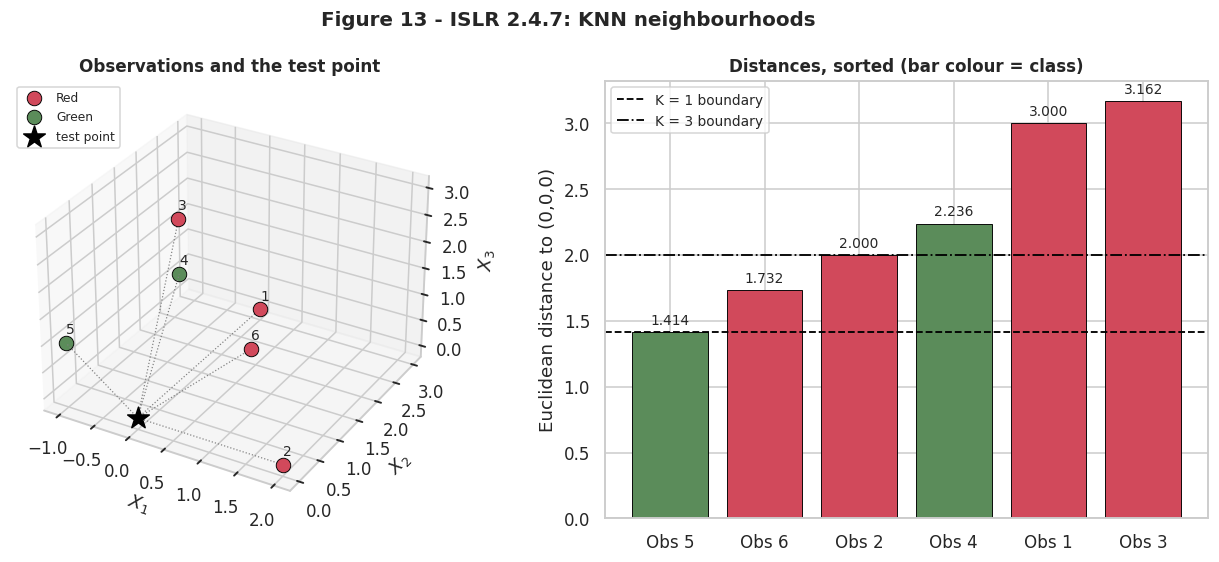

In [45]:
# Visualise both neighbourhoods.
fig = plt.figure(figsize=(12, 5.2))

ax = fig.add_subplot(121, projection="3d")
for label, colour in [("Red", RED), ("Green", GREEN)]:
    sel = islr[islr.Y == label]
    ax.scatter(sel.X1, sel.X2, sel.X3, s=90, color=colour,
               edgecolor="black", lw=0.6, label=label, depthshade=False)
ax.scatter(*test_point, s=220, marker="*", color="black", label="test point")
for obs, row in islr.iterrows():
    ax.plot([0, row.X1], [0, row.X2], [0, row.X3], color="grey", lw=0.8, ls=":")
    ax.text(row.X1, row.X2, row.X3 + 0.18, f"{obs}", fontsize=9)
ax.set_xlabel("$X_1$"); ax.set_ylabel("$X_2$"); ax.set_zlabel("$X_3$")
ax.set_title("Observations and the test point", fontsize=11)
ax.legend(fontsize=8, loc="upper left")

ax2 = fig.add_subplot(122)
srt = np.argsort(distances)
cols = [RED if islr.Y.iloc[i] == "Red" else GREEN for i in srt]
bars = ax2.bar([f"Obs {islr.index[i]}" for i in srt], distances[srt],
               color=cols, edgecolor="black", lw=0.6)
ax2.axhline(distances[srt][0], color="black", ls="--", lw=1.2,
            label="K = 1 boundary")
ax2.axhline(distances[srt][2], color="black", ls="-.", lw=1.2,
            label="K = 3 boundary")
for b, d in zip(bars, distances[srt]):
    ax2.text(b.get_x() + b.get_width() / 2, d + 0.06, f"{d:.3f}",
             ha="center", fontsize=9)
ax2.set_ylabel("Euclidean distance to (0,0,0)")
ax2.set_title("Distances, sorted (bar colour = class)", fontsize=11)
ax2.legend(fontsize=9)

fig.suptitle("Figure 13 - ISLR 2.4.7: KNN neighbourhoods",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

**Answer to 3 (c): Red.**

With $K = 3$ the three nearest neighbours are:

| Rank | Obs. | Distance | $Y$ |
|---|---|---|---|
| 1 | 5 | $\sqrt{2} = 1.414$ | Green |
| 2 | 6 | $\sqrt{3} = 1.732$ | **Red** |
| 3 | 2 | $\sqrt{4} = 2.000$ | **Red** |

The majority vote is **2 Red against 1 Green**, so the prediction is **Red**.
In probability terms, KNN estimates
$$P(Y = \text{Red} \mid X) = \tfrac{2}{3} \approx 0.667, \qquad
P(Y = \text{Green} \mid X) = \tfrac{1}{3} \approx 0.333,$$
and classifies to the larger.

Note that the prediction **changed** from Green ($K=1$) to Red ($K=3$). The
single nearest point was Green, but it was outvoted once the neighbourhood
widened — a concrete illustration of how sensitive $K=1$ is to individual
observations.

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

In [46]:
# ----------------------------------------------------------------------
# (d) Demonstration: a highly non-linear (circular) Bayes boundary.
#     Which K gives the lowest test error?
# ----------------------------------------------------------------------
def circular(n, rng, noise=0.02):
    """Data whose Bayes boundary is a circle of radius 2 - highly non-linear."""
    X = rng.uniform(-3, 3, size=(n, 2))
    y = ((X ** 2).sum(axis=1) > 4).astype(int)
    flip = rng.random(n) < noise                     # a little label noise
    return X, np.where(flip, 1 - y, y)


K_GRID_D = [1, 3, 5, 10, 25, 50, 100, 200]

# Average over 20 replications so the curve is not driven by one random draw.
errors = {k: [] for k in K_GRID_D}
for rep in range(20):
    rng = np.random.default_rng(100 + rep)
    Xa, ya = circular(400, rng)
    Xb, yb = circular(2000, rng)
    for k in K_GRID_D:
        clf = KNeighborsClassifier(n_neighbors=k).fit(Xa, ya)
        errors[k].append(1 - clf.score(Xb, yb))

demo = pd.DataFrame({"K": K_GRID_D,
                     "test error": [np.mean(errors[k]) for k in K_GRID_D]})
print("Highly non-linear (circular) Bayes boundary, averaged over 20 replications:")
print(demo.round(4).to_string(index=False))

best_k = int(demo.loc[demo["test error"].idxmin(), "K"])
worst = demo["test error"].iloc[-1]
print(f"\nBest K = {best_k} out of {{1, ..., 200}}  -> the optimum is at the SMALL end.")
print(f"At K = 200 the error is {worst:.4f}, roughly "
      f"{worst / demo['test error'].min():.1f}x the error at K = {best_k}.")

# One representative replication, kept for the decision-boundary plots below.
rng = np.random.default_rng(100)
Xtr_d, ytr_d = circular(400, rng)

Highly non-linear (circular) Bayes boundary, averaged over 20 replications:
  K  test error
  1      0.0688
  3      0.0562
  5      0.0555
 10      0.0591
 25      0.0606
 50      0.0684
100      0.0924
200      0.1999

Best K = 5 out of {1, ..., 200}  -> the optimum is at the SMALL end.
At K = 200 the error is 0.1999, roughly 3.6x the error at K = 5.


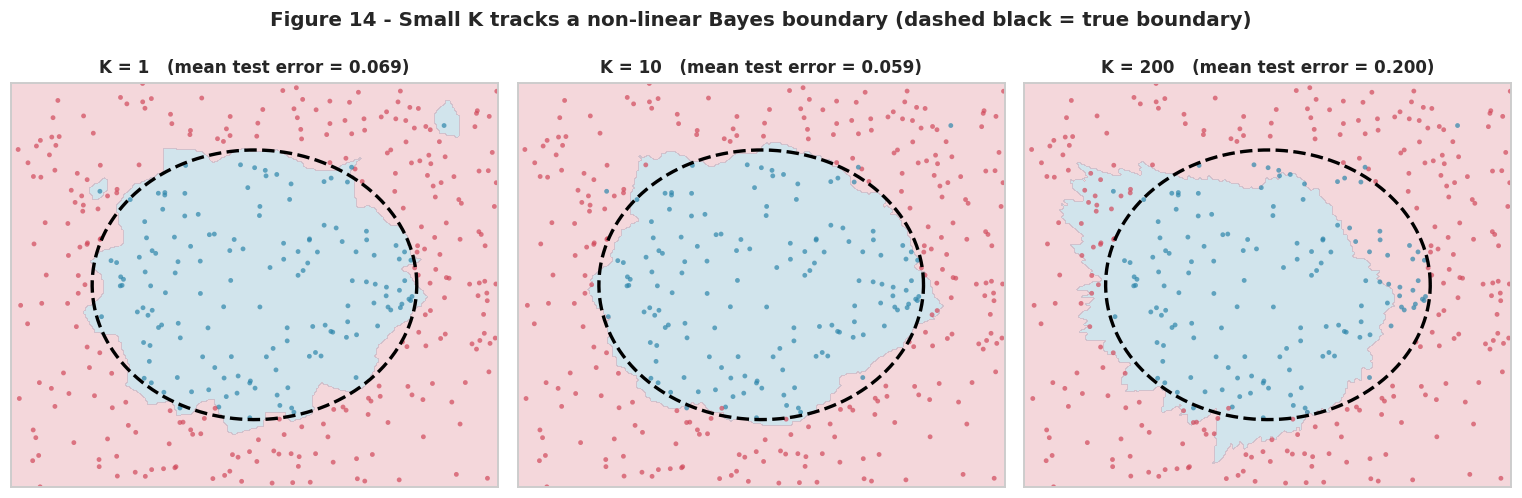

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
xx, yy = np.meshgrid(np.linspace(-3, 3, 220), np.linspace(-3, 3, 220))
grid = np.c_[xx.ravel(), yy.ravel()]

for ax, k in zip(axes, [1, 10, 200]):
    clf = KNeighborsClassifier(n_neighbors=min(k, len(Xtr_d))).fit(Xtr_d, ytr_d)
    zz = clf.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.22, levels=1, colors=[BLUE, RED])
    ax.scatter(Xtr_d[:, 0], Xtr_d[:, 1], c=[RED if v else BLUE for v in ytr_d],
               s=10, edgecolor="none", alpha=0.7)
    # True Bayes boundary: circle of radius 2.
    th = np.linspace(0, 2 * np.pi, 300)
    ax.plot(2 * np.cos(th), 2 * np.sin(th), color="black", lw=2.2, ls="--")
    err = demo.loc[demo.K == k, "test error"]
    ax.set_title(f"K = {k}   (mean test error = {float(err.iloc[0]):.3f})", fontsize=11)
    ax.set_xticks([]); ax.set_yticks([])

fig.suptitle("Figure 14 - Small K tracks a non-linear Bayes boundary "
             "(dashed black = true boundary)", fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

**Answer to 3 (d): SMALL.**

We would expect the best value of $K$ to be **small**.

**Why.** $K$ controls the flexibility of the KNN decision boundary, and it does
so *inversely*:

* **Small $K$** — the prediction at each point depends on only a few very close
  neighbours, so the fitted boundary can change direction rapidly. It is
  **flexible** and can trace a highly non-linear shape.
* **Large $K$** — the prediction averages over many neighbours drawn from a wide
  region, which smooths the boundary out. In the limit $K = n$ the boundary
  disappears entirely and every point is assigned the overall majority class.

If the true Bayes boundary is highly non-linear, a large $K$ imposes a smoother,
less flexible boundary that cannot match it, so the classifier suffers large
**bias**. A small $K$ keeps bias low and can follow the curvature.

Figure 14 demonstrates this with a circular Bayes boundary: $K=1$ and $K=10$
track the circle closely, while $K=200$ visibly distorts it — the fitted region
shrinks inside the true circle and grows ragged lobes — and the test error rises
sharply. Averaged over 20 replications the best value is
$K = 5$ out of the range $\{1, \dots, 200\}$ — firmly at the small end — and the
error at $K = 200$ is about 3.6 times larger.

**The trade-off still applies.** Small $K$ also means high **variance** — the
$K=1$ boundary in Figure 14 is visibly noisy around the edges. So "small" does
not mean $K=1$ is automatically optimal; it means the optimum sits at the low
end of the range, and the exact value should be chosen by cross-validation.

---

## References

1. UCI Machine Learning Repository — Combined Cycle Power Plant Data Set.
   <https://archive.ics.uci.edu/ml/datasets/Combined+Cycle+Power+Plant>
2. Pınar Tüfekci, *Prediction of full load electrical power output of a base
   load operated combined cycle power plant using machine learning methods*,
   International Journal of Electrical Power & Energy Systems, 60 (2014),
   126–140.
3. Heysem Kaya, Pınar Tüfekci, Sadık Fikret Gürgen, *Local and Global Learning
   Methods for Predicting Power of a Combined Gas & Steam Turbine*,
   Proceedings of ICETCEE 2012, 13–18.
4. James, G., Witten, D., Hastie, T., Tibshirani, R. *An Introduction to
   Statistical Learning* (ISLR), 2nd ed. — Ch. 2.2 (bias–variance trade-off,
   KNN), Ch. 3 (linear regression, interaction terms, the hierarchy principle),
   and exercises 2.4.1 and 2.4.7.
5. scikit-learn documentation — Generating polynomial features.
   <https://scikit-learn.org/stable/modules/preprocessing.html#generating-polynomial-features>
6. scikit-learn documentation — `KNeighborsRegressor`.
   <https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html>
7. statsmodels documentation — Ordinary Least Squares and `anova_lm`.
   <https://www.statsmodels.org/stable/regression.html>
8. statsmodels documentation — Outlier and influence measures
   (studentized residuals, Cook's distance).
   <https://www.statsmodels.org/stable/generated/statsmodels.stats.outliers_influence.OLSInfluence.html>